# 케미컬 탱커 월별 수주실적 다변량 분석

**이 노트북은 인력계획에 참고할 글로벌 케미컬 탱커 신규 수주용량의 월별 전망을 만듭니다.** 셀을 위에서부터 실행하면 입력 점검부터 모형 평가와 운영 전망까지 확인할 수 있습니다.

`data/master/마스터테이블(케미컬 탱커).csv`의 월별 자료를 탐색하고, D=C-3 자료월 경계를 지키며 사후 확보한 값까지 포함해 예측모형을 비교합니다.

- 목표변수: 월별 `수주용량` (DWT). 그래프에는 processed 수주실적의 컬럼명 `수주용량(DWT)`를 표시합니다.
- 예측 기준: 매월 말 `C`에서 3개월 전 자료월 `D=C-3`까지 사용하고, 그로부터 6개월 뒤인 `D+6`의 수주용량을 예측합니다.
- 설명변수: `D`·`D-1`·`D-2`의 확정 수주용량과 `D`까지 관측된 가격·운임·선복량·경기·위험 지표를 후보로 비교합니다. 세계 물동량은 최근 합계가 불완전해 제외합니다.
- 개발 검증: 2022~2024년의 여러 월말에서 D=C-3 자료월 경계 이내의 관측값으로 재학습하고, 연도별 walk-forward fold를 비교합니다.
- 모형·변수 선택: 전체 후보로 선형회귀·2차 다항 Ridge·랜덤 포레스트의 고정 설정을 비교한 뒤, 같은 fold에서 변수를 하나씩 제거합니다. 평균 sMAPE가 1%p 이상 낮아지고 3개 연도 중 2개 이상에서 개선될 때만 제거를 이어갑니다. 하이퍼파라미터는 튜닝하지 않습니다.
- 2025~2026년 개발 진단: 선택된 예측 규칙을 매월 적용한 실제·예측값을 비교합니다. 이미 살펴본 기간이므로 독립 테스트 성능으로 해석하지 않습니다.

후보 변수와 모형은 코드가 검증 결과로 선택하므로 사용자가 직접 고를 필요는 없습니다. 결측 수주용량은 0으로 채우지 않습니다.

예측 기준월 `C`와 자료월 `D`를 구분하는 이유는 자료 공개 지연 때문입니다. 예를 들어 2026년 10월 말에는 7월까지를 안정적으로 확보했다고 가정하므로 2027년 1월을 예측합니다. 동일한 h+6 규칙을 2026년 5~10월의 여섯 기준일에 순차 적용하면 2~7월 자료가 각각 8월~다음 해 1월 예측값을 만듭니다. 운영 그래프는 7월 이후 실제값을 가리고 이 여섯 점만 예측선으로 보여줍니다.

모형 선택의 주지표는 연도별 fold 평균 sMAPE이며 fold별 점수와 표준편차도 함께 확인합니다. MAE·RMSE·R²와 완전한 분기·반기·연간 누적 오차는 보조적으로 봅니다. 완전한 기간이 없으면 누적 점수를 만들지 않습니다.

모든 외부지표에는 공통 D=C-3 자료월 경계를 적용합니다. 수주실적은 사후 확인된 값을 포함하며 개별 기사 게시일로 사용을 막지 않습니다. 과거의 수정 전 자료 빈티지는 보존되지 않아 당시 시점의 완전한 재현은 아닙니다.
이 선종의 월별 수주실적은 현재 2016-06부터 확보되어 있습니다.


### 준비 1. 피처 목록·표시 설정

In [1]:
from pathlib import Path

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

선종 = '케미컬 탱커'
목표단위 = 'DWT'
종속변수 = '수주용량'
원자재원본피처 = ['원유 평균 가격(USD/bbl)', '팜유 가격(USD/mt)', '대두유 가격(USD/mt)', '천연가스 가격지수(2010=100)']
물동량원본피처 = []  # 2026년 이후 입력 불완전: 전 분석 후보에서 제외
벙커유원본피처 = ['싱가포르_벙커유판매량_천톤']
위험원본피처 = ['GPR(세계지정학위험지수)', 'GPRT(지정학위협지수)', 'GPRA(지정학행동지수)']
무역정책원본피처 = ['미국TPU(EPUTRADE 무역정책불확실성지수)', '미국TPU(Caldara 무역정책불확실성지수)', '중국TPU(무역정책불확실성지수)']
신조선가원본피처 = []
운임원본피처 = []
선복량원본피처 = []
컨테이너처리량원본피처 = ['글로벌_컨테이너처리량지수']
세계거시원본피처 = ['세계_실질상품수출_백만2010USD_계절조정', '세계_실질상품수입_백만2010USD_계절조정', '세계_산업생산_백만2010USD_계절조정']
공급망원본피처 = ['글로벌_공급망압력지수(표준편차)']
과거수주후보피처 = ['수주용량_최근확정1개월차', '수주용량_최근확정2개월차', '수주용량_최근확정3개월차']
과거수주피처 = [과거수주후보피처[0]]
원본피처 = [*원자재원본피처, *물동량원본피처, *벙커유원본피처, *컨테이너처리량원본피처, *세계거시원본피처, *공급망원본피처, *신조선가원본피처, *운임원본피처, *선복량원본피처, *위험원본피처, *무역정책원본피처, *과거수주후보피처]
난수시드 = 42

plt.rcParams['font.family'] = 'Malgun Gothic'
plt.rcParams['axes.unicode_minus'] = False
sns.set_theme(style='whitegrid', font='Malgun Gothic')

### 준비 2. 마스터 로드·단위 검사

In [2]:
현재경로 = Path.cwd()
프로젝트후보 = [현재경로, 현재경로.parent, 현재경로.parent.parent]
프로젝트폴더 = next(
    (경로 for 경로 in 프로젝트후보 if (경로 / 'data' / 'master' / f'마스터테이블({선종}).csv').exists()),
    None,
)
if 프로젝트폴더 is None:
    raise FileNotFoundError(f'마스터테이블({선종}).csv' + ' 파일을 찾을 수 없습니다.')

import sys

소스경로 = str(프로젝트폴더 / 'src')
if 소스경로 not in sys.path:
    sys.path.insert(0, 소스경로)
from ship_orders_forecasting.reporting import display_formatted as 표표시

마스터파일 = 프로젝트폴더 / 'data' / 'master' / f'마스터테이블({선종}).csv'
원본자료 = pd.read_csv(마스터파일, encoding='utf-8-sig')
# 그래프에는 processed 수주실적 CSV의 실제 용량 컬럼명을 그대로 씁니다.
수주실적파일 = 프로젝트폴더 / 'data' / 'processed' / 선종 / f'수주실적({선종}).csv'
종속변수표시명 = f'수주용량({목표단위})'
if 종속변수표시명 not in pd.read_csv(수주실적파일, encoding='utf-8-sig', nrows=0).columns:
    raise KeyError(f'{수주실적파일.name}에 {종속변수표시명} 컬럼이 없습니다.')
수주가용시차컬럼 = '수주정보시차(개월)'
필수컬럼 = ['기준월', '수주용량단위', 수주가용시차컬럼, 종속변수, *원본피처]
누락컬럼 = set(필수컬럼).difference(원본자료.columns)
if 누락컬럼:
    raise KeyError(f'마스터 테이블 누락 컬럼: {sorted(누락컬럼)}')

if not 원본자료['수주용량단위'].eq(목표단위).all():
    raise ValueError(f'{선종} 수주용량단위가 {목표단위}로 통일되지 않았습니다.')
자료 = 원본자료[필수컬럼].copy()
자료['기준월'] = pd.to_datetime(자료['기준월'], format='%Y-%m')
자료 = 자료.set_index('기준월').sort_index()
검증첫월 = pd.Timestamp('2022-01-01')
검증선택종료월 = 검증첫월 - pd.DateOffset(months=int(자료.loc[검증첫월, 수주가용시차컬럼]))
if 자료.index.duplicated().any():
    raise ValueError('기준월 중복이 있습니다.')

print(f'입력 파일: {마스터파일}')
print(f'분석 컬럼: {필수컬럼}')

입력 파일: G:\내 드라이브\SHI_DT_2nd_project\01 기획\Ship orders forcasting\data\master\마스터테이블(케미컬 탱커).csv
분석 컬럼: ['기준월', '수주용량단위', '수주정보시차(개월)', '수주용량', '원유 평균 가격(USD/bbl)', '팜유 가격(USD/mt)', '대두유 가격(USD/mt)', '천연가스 가격지수(2010=100)', '싱가포르_벙커유판매량_천톤', '글로벌_컨테이너처리량지수', '세계_실질상품수출_백만2010USD_계절조정', '세계_실질상품수입_백만2010USD_계절조정', '세계_산업생산_백만2010USD_계절조정', '글로벌_공급망압력지수(표준편차)', 'GPR(세계지정학위험지수)', 'GPRT(지정학위협지수)', 'GPRA(지정학행동지수)', '미국TPU(EPUTRADE 무역정책불확실성지수)', '미국TPU(Caldara 무역정책불확실성지수)', '중국TPU(무역정책불확실성지수)', '수주용량_최근확정1개월차', '수주용량_최근확정2개월차', '수주용량_최근확정3개월차']


## 1. EDA

1.1절은 원자료의 품질·기술통계를 살펴봅니다. 1.2~1.3절은 첫 검증시점 전에 학습 가능했던 행만 사용해 **입력월 D의 피처와 목표월 D+6의 수주용량**을 함께 탐색합니다.

### 1.1 입력 품질·기술통계

In [3]:
# 2022~2024 선택 fold의 끝까지를 탐색합니다. 운영 예측의 가용성은 2절에서 따로 적용합니다.
탐색자료 = 자료.loc[자료.index < pd.Timestamp('2025-01-01')].copy()
print('EDA 범위: 2024-12까지')

# 관측방법은 3열 processed 파일이 아닌 raw 원자료에 보존되어 있습니다.
원본수주파일 = 프로젝트폴더 / 'data' / 'raw' / '수주실적.csv'
원본수주자료 = pd.read_csv(
    원본수주파일, encoding='utf-8-sig',
    usecols=['frequency', 'period', 'vessel_type', 'observation_method', 'capacity_value'],
)
원본선종 = {
    '벌크선': 'Bulk Carrier', '케미컬 탱커': 'Chemical Tanker',
    '컨테이너선': 'Container', '가스 운반선': 'Gas Carrier', '유조선': 'Oil Tanker',
}[선종]
추론0건 = 원본수주자료.loc[
    원본수주자료['frequency'].eq('monthly')
    & 원본수주자료['vessel_type'].eq(원본선종)
    & 원본수주자료['period'].isin(탐색자료.index.strftime('%Y-%m'))
    & 원본수주자료['observation_method'].eq('derived_zero_from_exhaustive_monthly_total')
]
if not 추론0건['capacity_value'].eq(0).all():
    raise ValueError('월보 합계로 추론한 0건 행에 양수 수주용량이 있습니다.')

품질요약 = pd.DataFrame({
    '선종': [선종],
    '시작월': [탐색자료.index.min().strftime('%Y-%m')],
    '종료월': [탐색자료.index.max().strftime('%Y-%m')],
    '전체월수': [len(탐색자료)],
    '용량관측월수': [탐색자료[종속변수].notna().sum()],
    '용량결측월수': [탐색자료[종속변수].isna().sum()],
    '수주0건월수': [탐색자료[종속변수].eq(0).sum()],
    '그중월보합계추론0건월수': [len(추론0건)],
    '최근확정1개월차관측월수': [탐색자료[과거수주피처[0]].notna().sum()],
    '최근확정1개월차결측월수': [탐색자료[과거수주피처[0]].isna().sum()],
})
display(품질요약)

기술통계 = 탐색자료[[종속변수, *원본피처]].describe().T
표표시(기술통계, '{:.2f}')



EDA 범위: 2024-12까지


,선종,시작월,종료월,전체월수,용량관측월수,용량결측월수,수주0건월수,그중월보합계추론0건월수,최근확정1개월차관측월수,최근확정1개월차결측월수
0,케미컬 탱커,2016-06,2024-12,103,100,3,8,8,100,3


,count,mean,std,min,25%,50%,75%,max
수주용량,100.00,247558.52,238918.67,0.00,74824.50,191800.00,354572.50,1181550.00
원유 평균 가격(USD/bbl),103.00,67.21,18.15,21.00,53.60,66.80,79.45,116.80
팜유 가격(USD/mt),103.00,866.78,259.36,535.00,697.50,811.00,977.50,1777.00
대두유 가격(USD/mt),103.00,1040.32,314.19,680.00,800.00,912.00,1135.00,1963.00
천연가스 가격지수(2010=100),103.00,104.52,76.87,34.00,64.15,76.50,98.90,454.00
싱가포르_벙커유판매량_천톤,103.00,4181.86,279.04,3506.75,4005.88,4178.95,4318.95,5050.64
글로벌_컨테이너처리량지수,103.00,118.31,8.38,101.31,111.82,118.95,124.35,133.95
세계_실질상품수출_백만2010USD_계절조정,103.00,1352460.73,82687.90,1093664.00,1300228.00,1353009.00,1415082.50,1495398.00
세계_실질상품수입_백만2010USD_계절조정,103.00,1522166.52,233736.13,1170241.00,1345953.50,1437985.00,1706866.50,2030906.00
세계_산업생산_백만2010USD_계절조정,103.00,1747184.47,104772.56,1470000.00,1680000.00,1720000.00,1840000.00,1930000.00


### 1.2 상관관계 히트맵

2022-01 첫 검증시점 이전의 학습행만 사용합니다. 입력 피처는 데이터마감월 `D`, 목표 수주용량은 `D+6`에 놓고 공통 D=C-3 자료월 경계를 적용합니다. 개별 수주실적 기사 게시일은 제한하지 않습니다. 미국 TPU·세계 거시·지정학 계열은 이 **D→D+6 상관계수 절댓값**이 가장 큰 후보 1개씩만 히트맵에 남깁니다. 이는 그림용 선택이며, 2절 모델은 매 예측시점의 학습행에서 다시 선택합니다.

D→D+6 EDA: 첫 검증시점 2022-01-31 이전 학습행 53개
입력 D 2016-08~2021-04 → 목표 D+6 2017-02~2021-10


,계열,후보,D→D+6 상관계수,히트맵,|상관계수|
0,미국TPU,미국TPU(EPUTRADE 무역정책불확실성지수),-0.146,제외,0.146
1,미국TPU,미국TPU(Caldara 무역정책불확실성지수),-0.191,포함,0.191
2,세계거시,세계_실질상품수출_백만2010USD_계절조정,0.027,제외,0.027
3,세계거시,세계_실질상품수입_백만2010USD_계절조정,0.090,포함,0.090
4,세계거시,세계_산업생산_백만2010USD_계절조정,0.028,제외,0.028
5,지정학,GPR(세계지정학위험지수),-0.258,제외,0.258
6,지정학,GPRT(지정학위협지수),-0.332,포함,0.332
7,지정학,GPRA(지정학행동지수),-0.038,제외,0.038


,수주용량_확보월,수주용량_확보월1개월전,수주용량_확보월2개월전,원유 평균 가격(USD/bbl),팜유 가격(USD/mt),대두유 가격(USD/mt),천연가스 가격지수(2010=100),싱가포르_벙커유판매량_천톤,글로벌_컨테이너처리량지수,세계_실질상품수입_백만2010USD_계절조정,글로벌_공급망압력지수(표준편차),GPRT(지정학위협지수),미국TPU(Caldara 무역정책불확실성지수),중국TPU(무역정책불확실성지수),수주용량(DWT)
수주용량_확보월,1.00,0.02,0.08,0.07,0.13,0.18,-0.05,0.16,0.13,0.09,-0.03,0.04,-0.10,-0.03,-0.06
수주용량_확보월1개월전,0.02,1.00,0.02,0.05,0.17,0.27,-0.05,0.05,0.23,0.40,-0.05,0.26,0.03,-0.06,-0.05
수주용량_확보월2개월전,0.08,0.02,1.00,0.03,0.16,0.17,-0.03,0.24,0.26,0.25,-0.07,0.11,0.03,-0.00,-0.03
원유 평균 가격(USD/bbl),0.07,0.05,0.03,1.00,-0.17,0.04,0.71,-0.08,0.26,0.45,-0.41,0.47,0.55,0.22,-0.29
팜유 가격(USD/mt),0.13,0.17,0.16,-0.17,1.00,0.91,0.05,0.40,0.28,0.19,0.29,-0.22,-0.46,-0.23,0.25
대두유 가격(USD/mt),0.18,0.27,0.17,0.04,0.91,1.00,0.15,0.35,0.48,0.41,0.32,-0.12,-0.37,-0.18,0.11
천연가스 가격지수(2010=100),-0.05,-0.05,-0.03,0.71,0.05,0.15,1.00,0.20,0.13,0.18,-0.35,0.29,0.30,0.05,-0.10
싱가포르_벙커유판매량_천톤,0.16,0.05,0.24,-0.08,0.40,0.35,0.20,1.00,0.09,-0.04,0.21,-0.00,-0.28,-0.13,0.20
글로벌_컨테이너처리량지수,0.13,0.23,0.26,0.26,0.28,0.48,0.13,0.09,1.00,0.80,0.25,0.00,0.05,0.43,0.09
세계_실질상품수입_백만2010USD_계절조정,0.09,0.40,0.25,0.45,0.19,0.41,0.18,-0.04,0.80,1.00,0.07,0.17,0.16,0.34,0.09


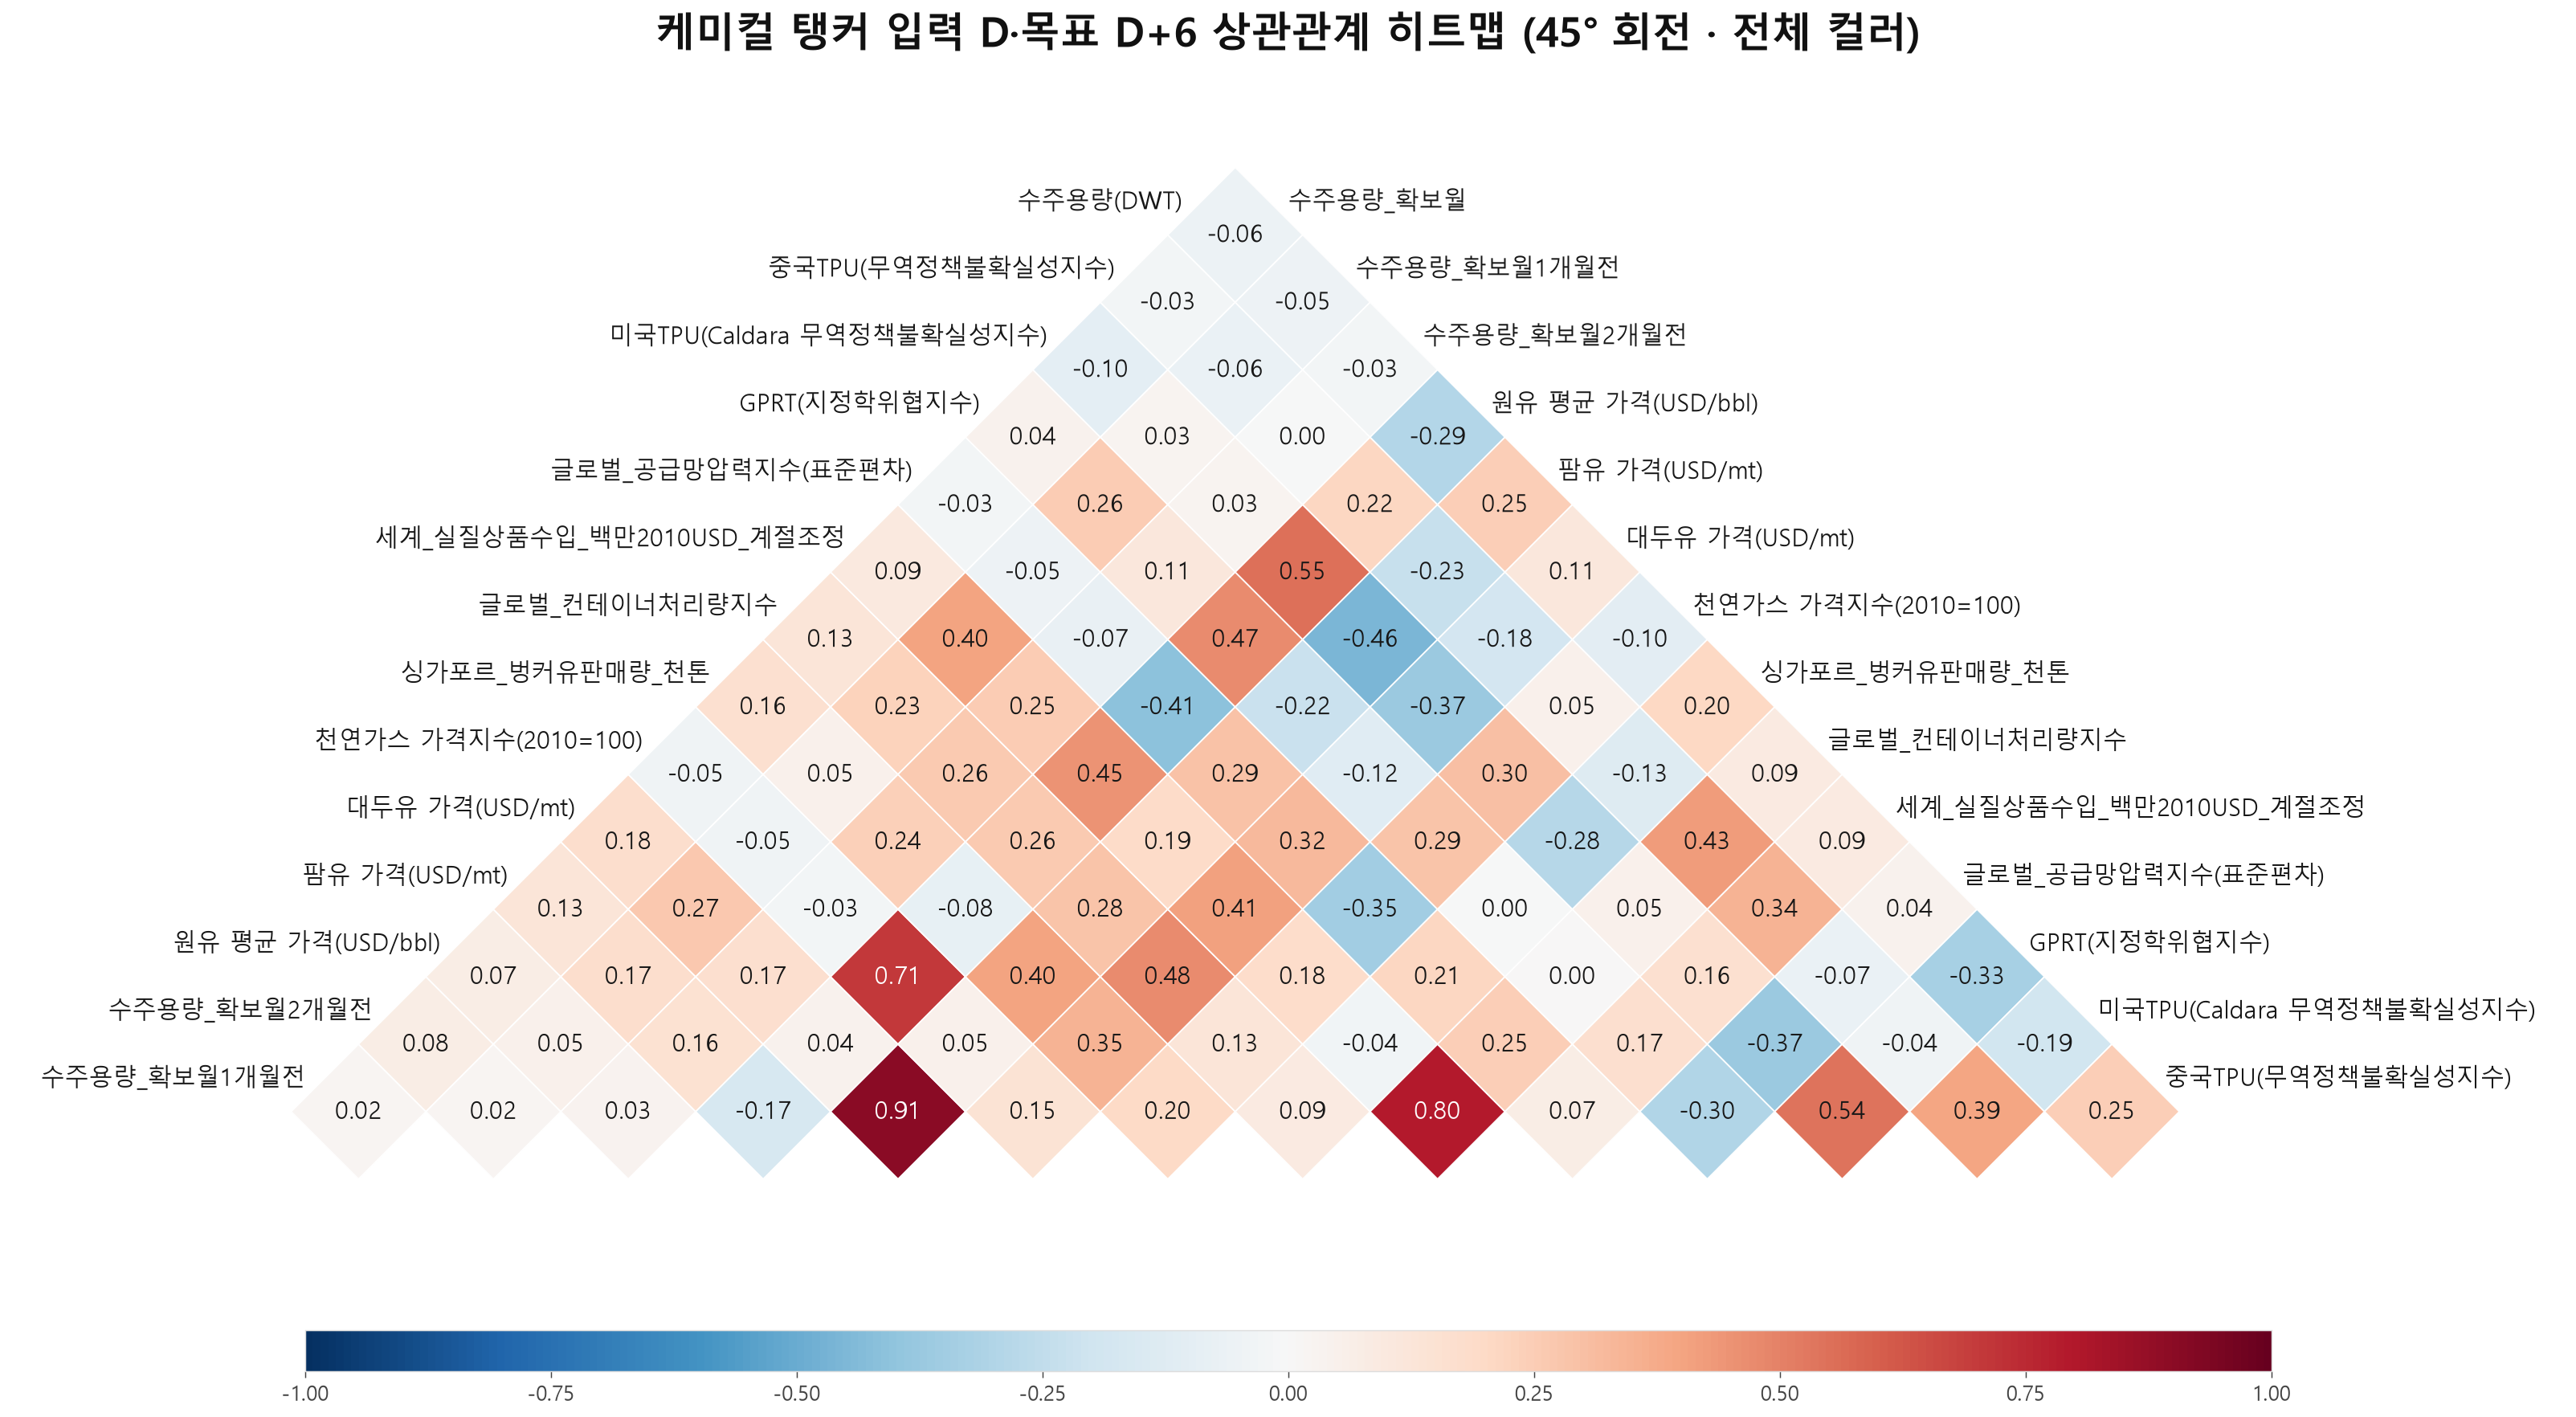

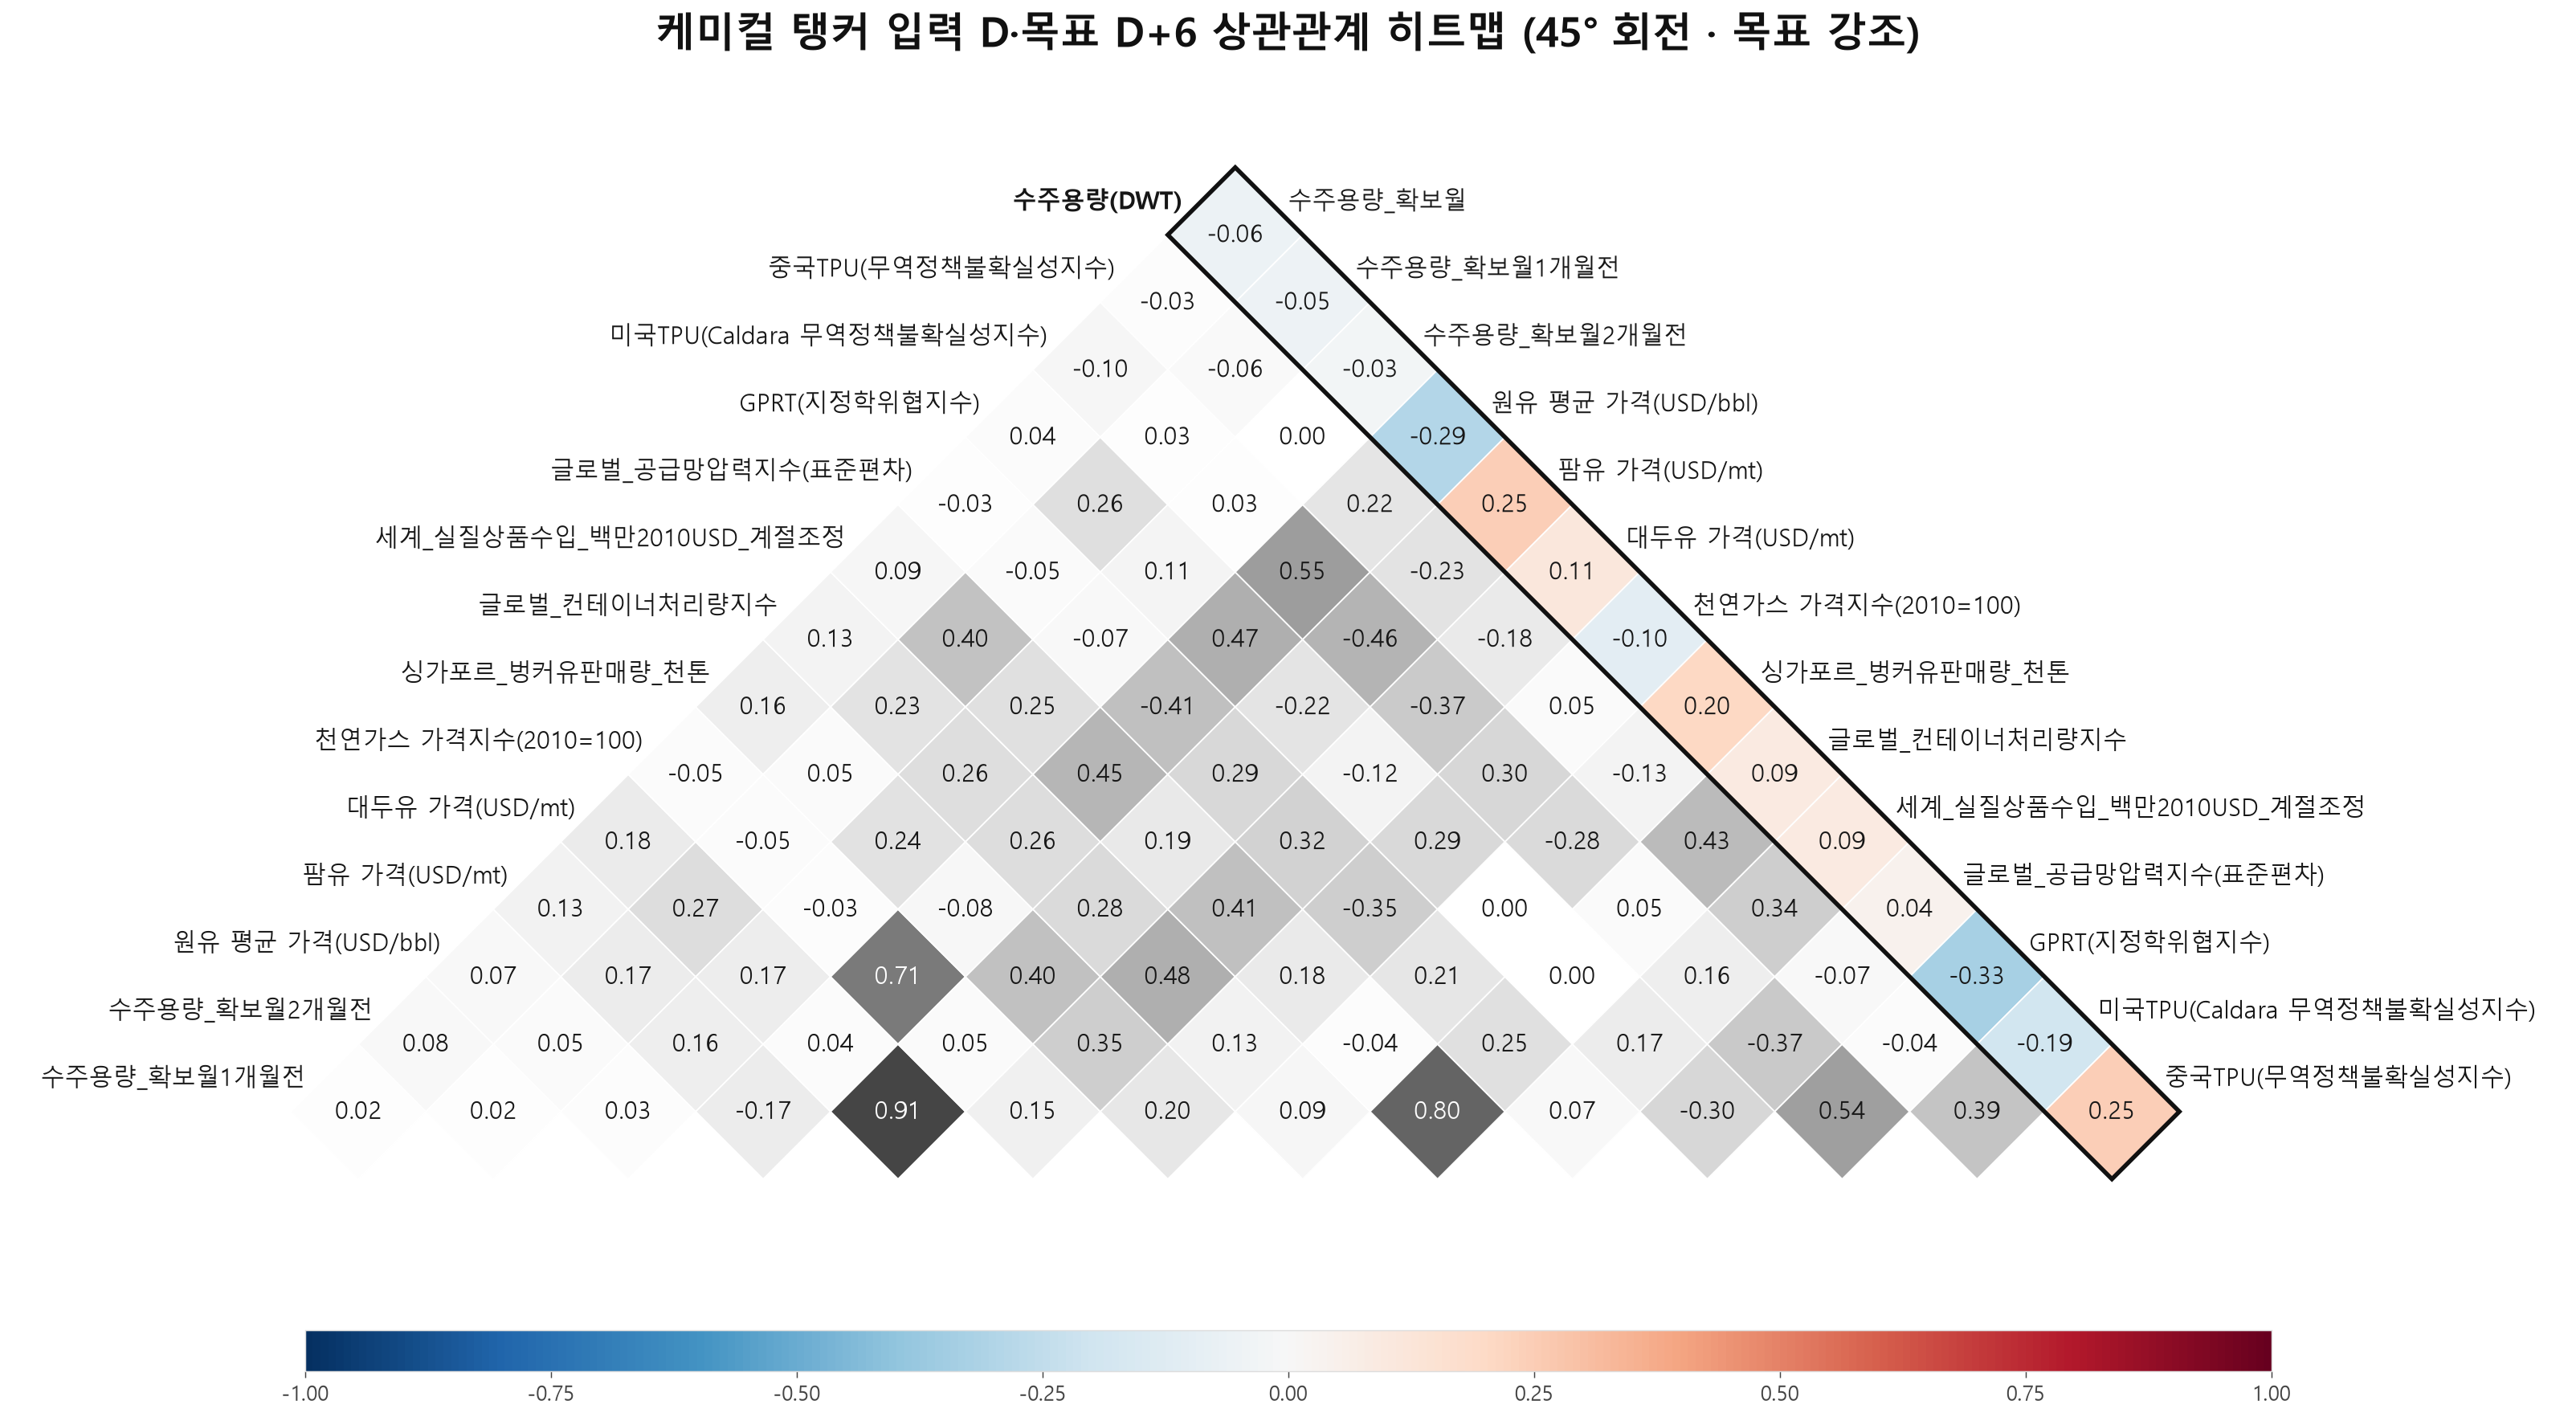

In [4]:
from ship_orders_forecasting.order_availability import publication_dates
from ship_orders_forecasting.publication_lag_forecast import (
    CORRELATION_GROUPS, MIN_TRAIN, ORDER_LAGS, direct_grid,
    eligible_training, month_end, select_correlated_features,
)
import runpy

# 모델과 같은 입력 생성 규칙을 쓰되, 첫 검증시점 직전의 학습행만 EDA에 사용합니다.
검증도구 = runpy.run_path(str(프로젝트폴더 / 'scripts' / '분석' / '2026_독립검증.py'))
시점프레임, 기존시차피처 = 검증도구['evaluation_frame'](선종, 검증도구['inputs']())
외부피처 = [피처.rsplit('_', 1)[0] for 피처 in 기존시차피처]
탐색외부피처 = [피처 for 피처 in 원본피처 if 피처 not in 과거수주후보피처]
if set(외부피처) != set(탐색외부피처):
    raise ValueError('EDA와 h+6 모형의 외부 후보 피처가 다릅니다.')
게시원본 = pd.read_csv(원본수주파일, encoding='utf-8-sig',
                 dtype=str, keep_default_na=False)
수주게시일원본 = publication_dates(게시원본, 원본선종)
# 사후 자료 완비 가정: D=C-3 달력 경계는 유지하되 개별 수주 월보의 실제 게시일은 제한하지 않습니다.
수주게시일 = pd.Series(pd.NaT, index=수주게시일원본.index, dtype='datetime64[ns]')
시점격자 = direct_grid(시점프레임, 외부피처, 수주게시일,
                  first_origin='2015-01', last_origin='2022-01')
첫검증시점 = month_end(pd.Timestamp('2022-01-01'))
그림후보 = [*ORDER_LAGS.values(), *외부피처]
초기학습 = eligible_training(시점격자, 6, 첫검증시점, 그림후보)
if len(초기학습) < MIN_TRAIN:
    raise ValueError(f'D→D+6 초기 학습행이 {MIN_TRAIN}개보다 적습니다.')
if not 초기학습['목표월'].eq(초기학습['데이터마감월'] + pd.DateOffset(months=6)).all():
    raise ValueError('EDA 입력월 D와 목표월 D+6이 맞지 않습니다.')
if 초기학습['목표월'].max() > pd.Timestamp('2021-10-01'):
    raise ValueError('EDA에 2022~2024 변수 선택구간의 목표값이 섞였습니다.')
print(f'D→D+6 EDA: 첫 검증시점 {첫검증시점:%Y-%m-%d} 이전 학습행 {len(초기학습)}개')
print(f'입력 D {초기학습["데이터마감월"].min():%Y-%m}~{초기학습["데이터마감월"].max():%Y-%m} '
      f'→ 목표 D+6 {초기학습["목표월"].min():%Y-%m}~{초기학습["목표월"].max():%Y-%m}')

# 그림용 계열 선택도 모델과 동일한 함수로, D→D+6 학습행에서만 계산합니다.
그림선택피처, 상관선택 = select_correlated_features(초기학습, 그림후보)
상관선택행 = []
for 계열, 그룹후보 in CORRELATION_GROUPS.items():
    후보 = [피처 for 피처 in 그룹후보 if 피처 in 그림후보]
    if len(후보) < 2:
        continue
    채택 = 상관선택[계열]['선택']
    상관선택행.extend({
        '계열': 계열, '후보': 피처,
        'D→D+6 상관계수': 초기학습[피처].corr(초기학습['실제']),
        '히트맵': '포함' if 피처 == 채택 else '제외',
    } for 피처 in 후보)
표 = pd.DataFrame(상관선택행)
표['|상관계수|'] = 표['D→D+6 상관계수'].abs()
display(표.round(3))

# 외부 피처끼리는 같은 D끼리, 목표와는 D→D+6으로 정렬된 상관행렬입니다.
상관입력 = 초기학습[[*그림선택피처, '실제']].rename(
    columns={'실제': 종속변수표시명})
상관열 = list(상관입력.columns)
상관관계 = 상관입력[상관열].corr(method='pearson')
표표시(상관관계, '{:.2f}')

회전그림도구 = runpy.run_path(str(프로젝트폴더 / 'scripts' / '분석' / '상관관계_회전히트맵.py'))
fig, 축 = 회전그림도구['draw_rotated_correlation'](
    상관관계, target=종속변수표시명, target_label=종속변수표시명,
    highlight_target=False,
    title=f'{선종} 입력 D·목표 D+6 상관관계 히트맵 (45° 회전 · 전체 컬러)',
)
plt.show()

fig, 축 = 회전그림도구['draw_rotated_correlation'](
    상관관계, target=종속변수표시명, target_label=종속변수표시명,
    highlight_target=True,
    title=f'{선종} 입력 D·목표 D+6 상관관계 히트맵 (45° 회전 · 목표 강조)',
)
plt.show()

### 1.3 박스플롯

박스플롯도 1.2절의 D→D+6 초기 학습행에서 선택된 수치형 변수만 표시합니다. 같은 후보군에서 그림용으로 제외된 열은 다시 그리지 않습니다.

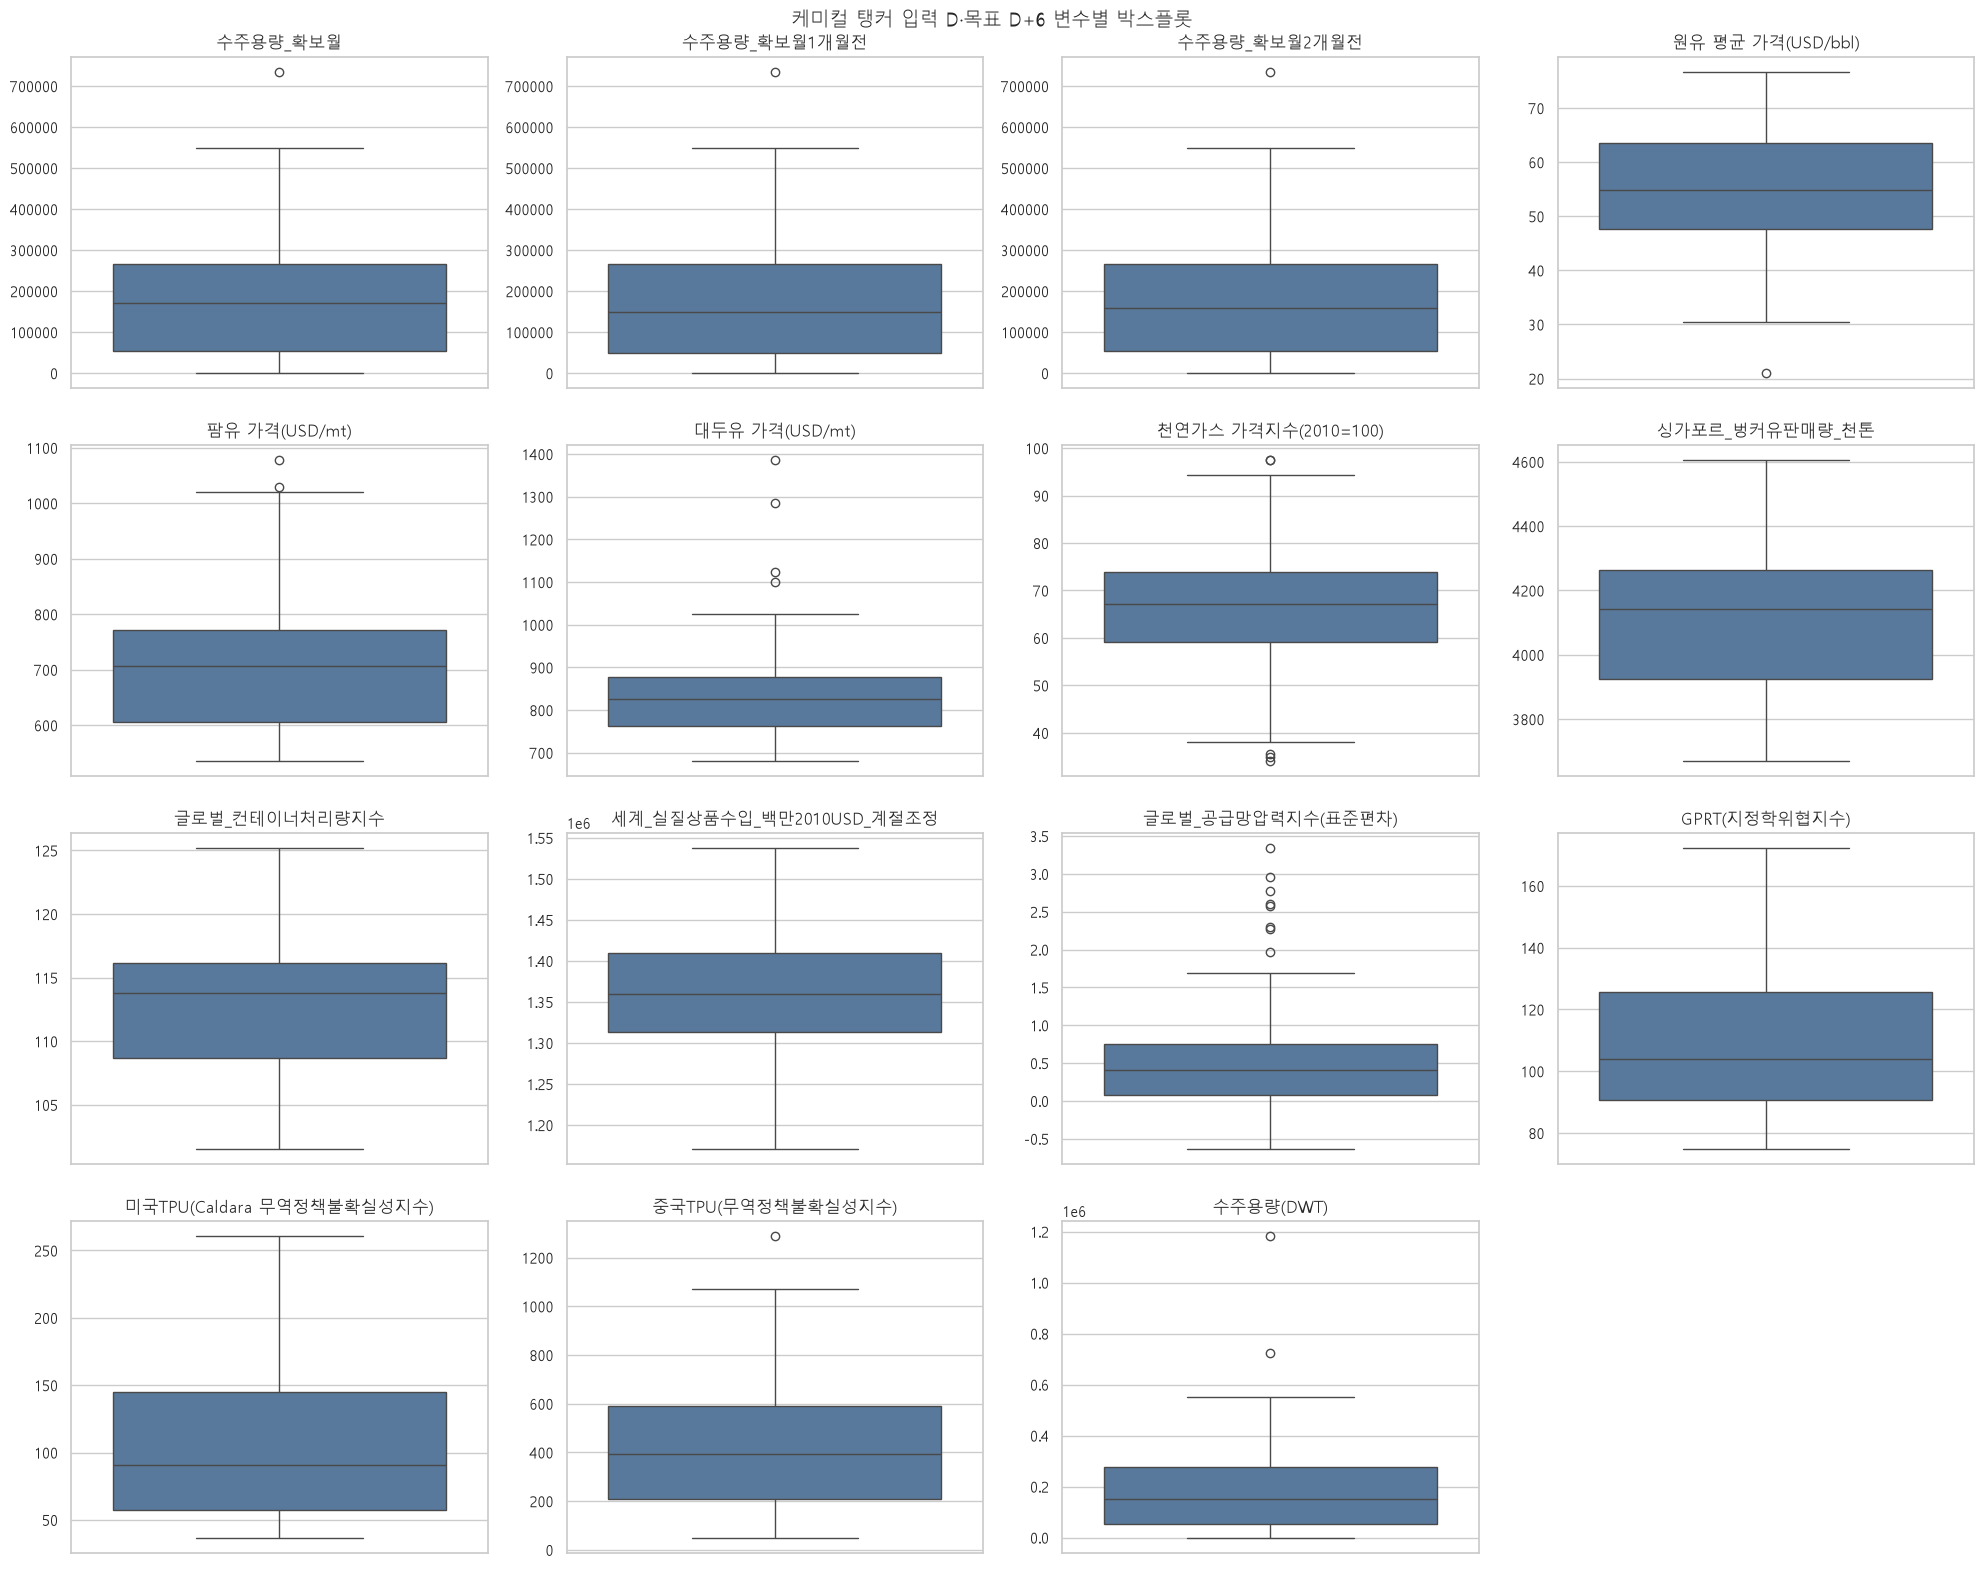

In [5]:
박스플롯자료 = 상관입력[상관열].copy()
박스플롯컬럼 = list(박스플롯자료.columns)
박스열수 = 4
박스행수 = int(np.ceil(len(박스플롯컬럼) / 박스열수))
fig, 축목록 = plt.subplots(박스행수, 박스열수, figsize=(5.0 * 박스열수, 4.0 * 박스행수), squeeze=False)
for 축, 컬럼 in zip(축목록.flat, 박스플롯컬럼):
    sns.boxplot(y=박스플롯자료[컬럼].dropna(), ax=축, color='#4C78A8')
    축.set_title(컬럼)
    축.set_xlabel('')
    축.set_ylabel('')
for 축 in 축목록.flat[len(박스플롯컬럼):]:
    축.axis('off')
fig.suptitle(f'{선종} 입력 D·목표 D+6 변수별 박스플롯', fontsize=14)
plt.tight_layout()
plt.show()

## 2. 전체 후보 모델과 시계열 검증

매월 말 예측기준월 `C`에서 3개월의 공통 공개 지연을 적용해 데이터마감월 `D=C-3`을 정합니다. 그 시점에 알 수 있는 수주 이력과 외부지표로 **목표월 `D+6`의 수주용량 한 달치**를 예측합니다. 과거 월별 검증과 현재 운영 전망도 같은 규칙을 반복 적용합니다.

### 2.1 공표 시차 정책·전체 후보 준비

In [6]:
import runpy

분석코드파일 = 프로젝트폴더 / 'scripts' / '분석' / '공개시차_6개월_선종별.py'
분석결과 = runpy.run_path(str(분석코드파일))['run_analysis'](선종)
if 분석결과['선종'] != 선종 or len(분석결과['결과']) != 1:
    raise ValueError('선종별 h+6 단일 목표 결과가 아닙니다.')
운영결과 = 분석결과['결과'][0]
if 운영결과['선행개월'] != 6:
    raise ValueError('예측 목표는 자료 기준 h+6이어야 합니다.')
데이터마감월 = pd.Timestamp(분석결과['최신허용데이터월'] + '-01')
예측기준월 = pd.Timestamp(분석결과['운영기준월'] + '-01')
운영예측 = 운영결과['2026-10-30_운영예측']
목표월 = (pd.Timestamp(운영예측['목표월'] + '-01')
       if 운영예측 is not None else 데이터마감월 + pd.DateOffset(months=6))
if 운영예측 is None:
    print('현재 기준 h+6 운영 예측 불가: 필요한 입력값이 비어 있습니다.')
if (데이터마감월 != 예측기준월 - pd.DateOffset(months=3)
        or 목표월 != 데이터마감월 + pd.DateOffset(months=6)):
    raise ValueError('공개 지연 3개월·선행예측 6개월 시점이 맞지 않습니다.')
운영전망선 = pd.DataFrame(운영결과['2026-10_6개월전망선'])
운영전망선['데이터마감월'] = pd.to_datetime(운영전망선['데이터마감월'])
운영전망선['목표월'] = pd.to_datetime(운영전망선['목표월'])
운영전망선 = 운영전망선.sort_values('목표월').reset_index(drop=True)
예상마감월 = pd.date_range(데이터마감월 - pd.DateOffset(months=5), periods=6, freq='MS')
예상목표월 = pd.date_range(데이터마감월 + pd.DateOffset(months=1), periods=6, freq='MS')
if (not 운영전망선['데이터마감월'].equals(pd.Series(예상마감월, name='데이터마감월'))
        or not 운영전망선['목표월'].equals(pd.Series(예상목표월, name='목표월'))
        or not 운영전망선['선행개월'].eq(6).all()):
    raise ValueError('여섯 h+6 예측의 입력월·목표월이 연속되지 않습니다.')
print(f'월말 기준 {예측기준월:%Y-%m} → 자료마감 {데이터마감월:%Y-%m} → 목표 {목표월:%Y-%m}')
print('가용성 한계:', 분석결과['가용성한계'])
if 운영전망선['예측'].isna().any():
    print('입력 결측으로 예측할 수 없는 목표월:',
          운영전망선.loc[운영전망선['예측'].isna(), '목표월'].dt.strftime('%Y-%m').tolist())

케미컬 탱커 h+6: 공개시차를 적용한 월별 순차 검증


월말 기준 2026-10 → 자료마감 2026-07 → 목표 2027-01
가용성 한계: 공통 D=C-3 자료월 경계는 유지하고 개별 수주실적 게시일 제한은 적용하지 않음. 사후 확보한 관측값도 포함될 수 있으며 당시 수정 전 빈티지는 보존되지 않음. 실제 관측값이 없는 월은 0이나 직전값으로 채우지 않음.


### 2.2 월별 순차평가 규칙

각 기준월마다 D=C-3 자료월 경계까지의 입력과 목표값만 사용합니다. 개별 기사 게시일은 제한하지 않습니다. 학습 후 그 기준월의 `D+6`을 한 번 예측한 뒤 기준월을 한 달 이동합니다. 아래 표의 여섯 행은 서로 다른 선행개월 모형이 아니라 **동일한 h+6 규칙을 여섯 번 적용한 결과**입니다.

In [7]:
from ship_orders_forecasting.publication_lag_forecast import (
    MIN_TRAIN, ORDER_LAGS, PUBLICATION_LAG_MONTHS, data_cutoff, eligible_training, predict_at,
)

if PUBLICATION_LAG_MONTHS != 3 or MIN_TRAIN != 36:
    raise ValueError('노트북의 공개 지연·최소 학습행 설명과 평가 코드가 다릅니다.')
display(운영전망선.assign(
    예측기준일=pd.to_datetime(운영전망선['예측기준일']).dt.strftime('%Y-%m'),
    데이터마감월=운영전망선['데이터마감월'].dt.strftime('%Y-%m'),
    목표월=운영전망선['목표월'].dt.strftime('%Y-%m'),
    학습라벨종료월=pd.to_datetime(운영전망선['학습라벨종료월']).dt.strftime('%Y-%m')
)[['예측기준일', '데이터마감월', '목표월', '학습라벨종료월', '학습행수']])
print('평가 함수: 기준월 입력 확인 → 데이터마감월까지의 목표값만 학습 → D+6 예측')

,예측기준일,데이터마감월,목표월,학습라벨종료월,학습행수
0,2026-05,2026-02,2026-08,2026-02,100
1,2026-06,2026-03,2026-09,2026-03,101
2,2026-07,2026-04,2026-10,2026-04,102
3,2026-08,2026-05,2026-11,2026-05,103
4,2026-09,2026-06,2026-12,2026-06,104
5,2026-10,2026-07,2027-01,2026-07,105


평가 함수: 기준월 입력 확인 → 데이터마감월까지의 목표값만 학습 → D+6 예측


### 2.3 외부지표 입력 시차

모든 외부지표는 기준월 `C`보다 3개월 앞선 **데이터마감월 `D`의 마스터 값**을 후보로 사용합니다. 검토한 원천의 최근 확보 가능 시점에 맞춘 공통 운영 규칙이며, 개별 지표가 이보다 먼저 나와도 추가 탈락시키지 않습니다. 관측값이 실제로 없으면 미래값·직전값으로 대체하지 않습니다. 미국 TPU 두 계열, 세계 거시 세 계열, 지정학 세 계열은 각각 예측시점의 학습자료에서 목표값과 상관계수 절댓값이 가장 큰 하나만 실제 모형에 투입합니다. 과거 발표 당시의 수정 전 값은 보존되지 않았습니다.

In [8]:
후보군 = 분석결과['후보군']
전체외부지표 = [피처 for 피처 in 후보군['전체 후보']
           if not 피처.startswith('수주용량_')]
외부시차표 = pd.DataFrame({
    '외부지표': 전체외부지표,
    '입력 관측월': ['D (= C-3)'] * len(전체외부지표),
    '입력 규칙': ['공통 D-3 관측월'] * len(전체외부지표),
})
display(외부시차표)

# 선택된 모형이 해당 그룹을 사용하는 경우에만 실제 투입 피처가 기록됩니다.
상관선택이력 = pd.DataFrame([
    {'목표월': 행['목표월'], '계열': 계열, '실제투입피처': 값['선택'],
     '학습상관계수': 값['학습상관계수']}
    for 행 in 운영결과['선택구간순차예측_참고']
    for 계열, 값 in 행.get('상관선택', {}).items()
])
if not 상관선택이력.empty:
    display(상관선택이력)

,외부지표,입력 관측월,입력 규칙
0,원유 평균 가격(USD/bbl),D (= C-3),공통 D-3 관측월
1,팜유 가격(USD/mt),D (= C-3),공통 D-3 관측월
2,대두유 가격(USD/mt),D (= C-3),공통 D-3 관측월
3,천연가스 가격지수(2010=100),D (= C-3),공통 D-3 관측월
4,싱가포르_벙커유판매량_천톤,D (= C-3),공통 D-3 관측월
5,글로벌_컨테이너처리량지수,D (= C-3),공통 D-3 관측월
6,세계_실질상품수출_백만2010USD_계절조정,D (= C-3),공통 D-3 관측월
7,세계_실질상품수입_백만2010USD_계절조정,D (= C-3),공통 D-3 관측월
8,세계_산업생산_백만2010USD_계절조정,D (= C-3),공통 D-3 관측월
9,글로벌_공급망압력지수(표준편차),D (= C-3),공통 D-3 관측월


,목표월,계열,실제투입피처,학습상관계수
0,2022-04,미국TPU,미국TPU(Caldara 무역정책불확실성지수),-0.196382
1,2022-04,세계거시,세계_실질상품수입_백만2010USD_계절조정,0.088555
2,2022-04,지정학,GPR(세계지정학위험지수),-0.245838
3,2022-05,미국TPU,미국TPU(Caldara 무역정책불확실성지수),-0.178325
4,2022-05,세계거시,세계_실질상품수입_백만2010USD_계절조정,0.061731
...,...,...,...,...
85,2025-02,세계거시,세계_실질상품수입_백만2010USD_계절조정,0.302911
86,2025-02,지정학,GPRA(지정학행동지수),0.244335
87,2025-03,미국TPU,미국TPU(Caldara 무역정책불확실성지수),-0.205789
88,2025-03,세계거시,세계_실질상품수입_백만2010USD_계절조정,0.321406


### 2.4 수주 이력 시차 후보

수주실적은 raw→processed 단계에서 기준월의 정확히 1·2·3개월 전 값을 미리 만듭니다. 이 분석은 데이터마감월 `D`의 원값과 가공본에서 가져온 `D-1`, `D-2`를 **각 한 달 수주용량** 후보로 씁니다. `D-3`도 가공본에는 보존하지만 현재 후보에는 넣지 않습니다. 결측월을 0이나 직전 관측월로 채우지 않으며, 개별 기사 게시일은 사용 제한에 적용하지 않습니다.

In [9]:
# 2.1절에서 메모리로 계산한 전체 후보를 그대로 사용합니다.
선택 = 운영결과['선택']
수주후보 = list(ORDER_LAGS.values())
if len(수주후보) != 3 or any('5개월전' in 피처 for 피처 in 수주후보):
    raise RuntimeError('수주 시차 후보가 예상한 D·D-1·D-2와 다릅니다.')

수주시차표 = pd.DataFrame([
    {'자료 기준 선행개월': 선행개월, '피처': 피처,
     '실제 입력월': 'D' if 선행개월 == 1 else f'D-{선행개월 - 1}',
     '자료 형태': '해당 월 한 달 수주용량'}
    for 선행개월, 피처 in enumerate(수주후보, start=1)
])
if set(수주후보) != set(피처 for 피처 in 후보군['전체 후보']
                          if 피처.startswith('수주용량_')):
    raise ValueError('수주 이력 시차 설명과 실제 후보군이 다릅니다.')
display(수주시차표)
후보군표 = pd.DataFrame([{
    '변수조합': 이름,
    '수주 이력 피처 수': sum(피처.startswith('수주용량_') for 피처 in 목록),
    '외부지표 수': sum(not 피처.startswith('수주용량_') for 피처 in 목록),
    '전체 피처 수': len(목록),
    '외부지표': ', '.join(피처 for 피처 in 목록 if not 피처.startswith('수주용량_')) or '없음',
} for 이름, 목록 in 후보군.items()])
display(후보군표)

,자료 기준 선행개월,피처,실제 입력월,자료 형태
0,1,수주용량_확보월,D,해당 월 한 달 수주용량
1,2,수주용량_확보월1개월전,D-1,해당 월 한 달 수주용량
2,3,수주용량_확보월2개월전,D-2,해당 월 한 달 수주용량


,변수조합,수주 이력 피처 수,외부지표 수,전체 피처 수,외부지표
0,전체 후보,3,16,19,"원유 평균 가격(USD/bbl), 팜유 가격(USD/mt), 대두유 가격(USD/m..."


### 2.5 입력 피처·공통 검증월 확정

2022·2023·2024년의 월별 walk-forward 기준월 중에서 **전체 후보 모형과 변수 제거 시험이 공통으로 평가 가능한 월**만 사용합니다. 데이터마감월 이후 입력과 데이터마감월 이후의 목표값은 학습에서 제외하되, 개별 수주실적 기사 게시일은 제한하지 않습니다. 목표값이 없거나 학습행이 36개 미만인 기준월도 제외합니다.

In [10]:
선택 = 운영결과['선택']
fold월 = 선택['fold별기준월']
fold요약 = pd.DataFrame([{'fold': 연도, '평가 기준월 수': len(월목록),
                     '첫 기준월': 월목록[0], '마지막 기준월': 월목록[-1]}
                    for 연도, 월목록 in fold월.items()])
display(fold요약)
검증월행 = []
for 연도, 월목록 in fold월.items():
    for 월 in 월목록:
        기준월 = pd.Timestamp(월 + '-01')
        마감월 = 기준월 - pd.DateOffset(months=3)
        검증월행.append({'fold': 연도, '예측 기준월': 월,
                 '입력 마감월': 마감월.strftime('%Y-%m'),
                 '목표월(D+6)': (마감월 + pd.DateOffset(months=6)).strftime('%Y-%m')})
display(pd.DataFrame(검증월행))
print('최소 학습행수: 36. 검증월 목록은 모든 후보군이 평가 가능한 월의 교집합입니다.')

,fold,평가 기준월 수,첫 기준월,마지막 기준월
0,2022,12,2022-01,2022-12
1,2023,7,2023-01,2023-09
2,2024,4,2024-04,2024-07


,fold,예측 기준월,입력 마감월,목표월(D+6)
0,2022,2022-01,2021-10,2022-04
1,2022,2022-02,2021-11,2022-05
2,2022,2022-03,2021-12,2022-06
3,2022,2022-04,2022-01,2022-07
4,2022,2022-05,2022-02,2022-08
5,2022,2022-06,2022-03,2022-09
6,2022,2022-07,2022-04,2022-10
7,2022,2022-08,2022-05,2022-11
8,2022,2022-09,2022-06,2022-12
9,2022,2022-10,2022-07,2023-01


최소 학습행수: 36. 검증월 목록은 모든 후보군이 평가 가능한 월의 교집합입니다.


### 2.6 기준값·전체 후보 모형 비교

최근 확보월 수주용량과 최근 3개월 평균을 기준값으로 둡니다. 사전에 만든 변수 묶음 없이 **전체 후보 하나**로 세 고정 모형을 같은 fold에서 비교합니다. 평균 sMAPE가 낮을수록 좋으며, fold별 점수와 표준편차를 함께 봅니다. 아직 하이퍼파라미터는 조정하지 않습니다.

,기준모형,2022 sMAPE(%),2023 sMAPE(%),2024 sMAPE(%),fold 평균(%),fold 표준편차(%p)
0,확보월 수주용량 유지,110.1,65.5,65.7,80.4,25.7
1,확보월까지 3개월 수주용량 평균,92.4,62.9,46.7,67.3,23.2


,모형,피처 수,2022 sMAPE(%),2023 sMAPE(%),2024 sMAPE(%),fold 평균(%),fold 표준편차(%p)
0,랜덤 포레스트,19,106.5,85.2,48.9,80.2,29.1
1,2차 다항 Ridge,19,181.7,69.8,67.0,106.2,65.4
2,1차 선형회귀,19,172.7,97.3,68.3,112.7,53.9


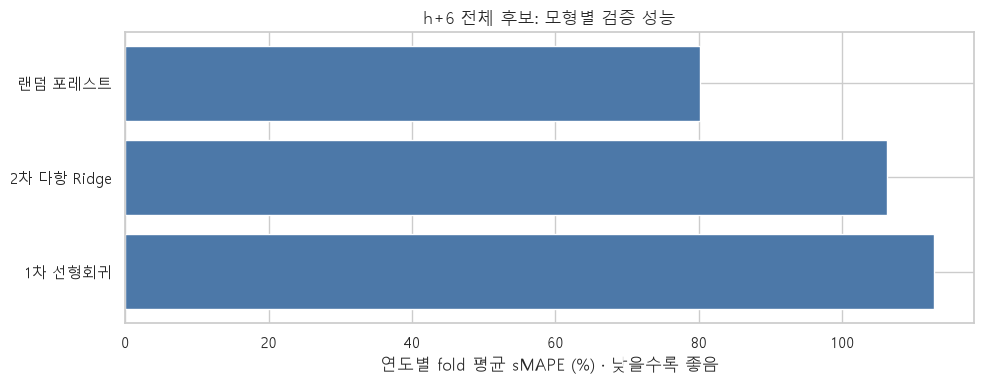

In [11]:
기준값표 = pd.DataFrame([{
    '기준모형': 행['기준모형'],
    **{f'{연도} sMAPE(%)': 100 * 점수 for 연도, 점수 in 행['fold별sMAPE'].items()},
    'fold 평균(%)': 100 * 행['평균sMAPE'],
    'fold 표준편차(%p)': 100 * 행['표준편차'],
} for 행 in 운영결과['기준모형비교']])
display(기준값표.round(1))

초기모형행 = [행 for 행 in 운영결과['변수조합비교'] if '제거변수' not in 행]
초기모형표 = pd.DataFrame([{
    '모형': 행['모형'], '피처 수': len(행['피처목록']),
    **{f'{연도} sMAPE(%)': 100 * 점수 for 연도, 점수 in 행['fold별sMAPE'].items()},
    'fold 평균(%)': 100 * 행['평균sMAPE'],
    'fold 표준편차(%p)': 100 * 행['표준편차'],
} for 행 in 초기모형행]).sort_values('fold 평균(%)')
display(초기모형표.round(1))
fig, 축 = plt.subplots(figsize=(10, 4))
축.barh(초기모형표['모형'][::-1], 초기모형표['fold 평균(%)'][::-1], color='#4C78A8')
축.set_title('h+6 전체 후보: 모형별 검증 성능')
축.set_xlabel('연도별 fold 평균 sMAPE (%) · 낮을수록 좋음')
fig.tight_layout()
plt.show()

## 3. 피처 중요도와 자동 변수 선택

2절에서 전체 후보의 fold 평균 sMAPE가 가장 낮은 모형을 고른 뒤, **같은 검증월**에서 피처를 하나씩 제거해 봅니다. 제거 후 평균이 1%p 이상 좋아지고 세 fold 중 최소 둘에서 개선될 때만 채택하며, 개선이 멈출 때까지 반복합니다.

### 3.1 한 변수 제거 진단

각 점은 해당 변수를 **제거한 뒤의 sMAPE 값**입니다. 점선은 그 단계의 제거 전 점수입니다. 왼쪽은 개선, 오른쪽은 악화이며 금색 점만 실제로 제거했습니다. `%p` 변화량은 표에서만 확인합니다.

,단계,제거 변수,제거 전 평균(%),제거 후 평균(%),2022 개선(%p),2023 개선(%p),2024 개선(%p)
14,1,GPRT(지정학위협지수),80.20,74.39,9.64,7.79,0.00
19,2,수주용량_확보월,74.39,72.23,-3.34,5.44,4.39
43,3,싱가포르_벙커유판매량_천톤,72.23,70.44,6.03,-3.38,2.71
57,4,팜유 가격(USD/mt),70.44,69.14,-0.44,3.13,1.21


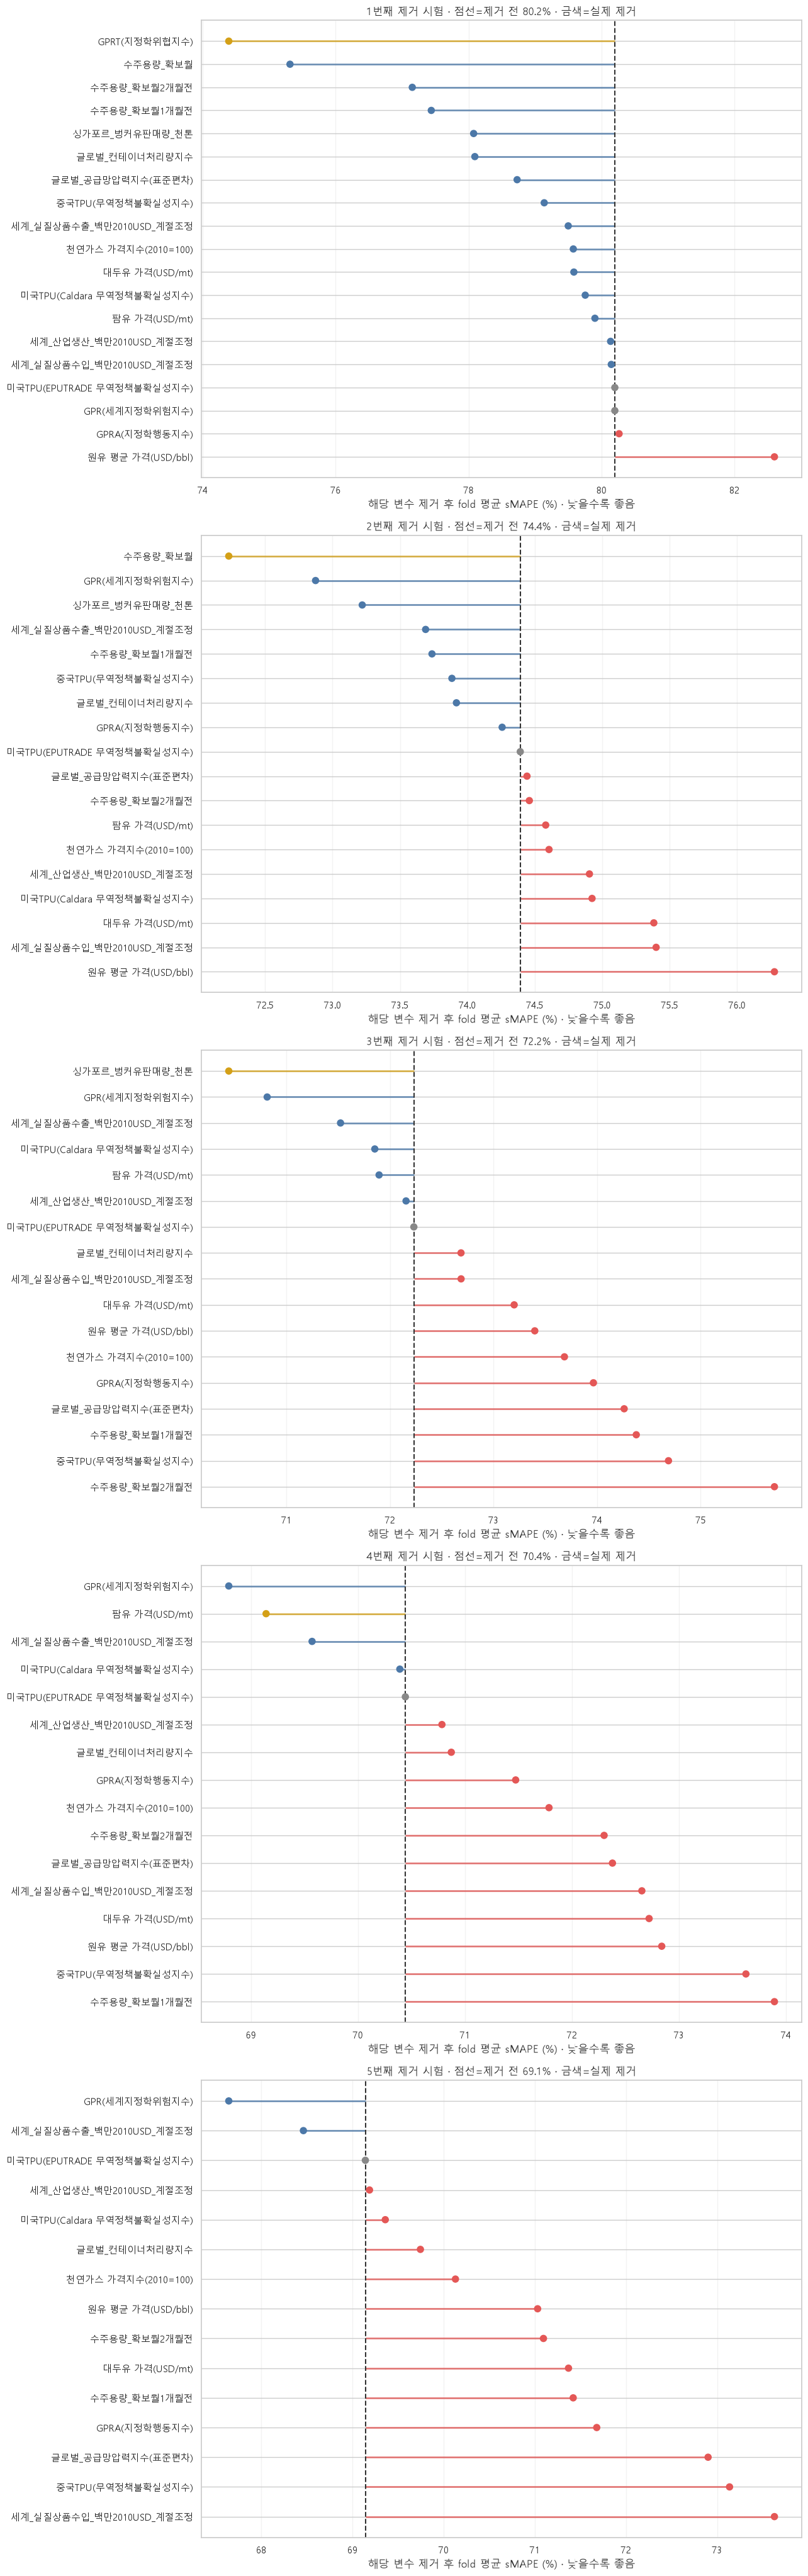

In [12]:
제거시험 = pd.DataFrame([{
    '단계': 행['단계'], '제거 변수': 행['제거변수'],
    '제거 전 평균(%)': 100 * 행['제거전평균sMAPE'],
    '제거 후 평균(%)': 100 * 행['제거후평균sMAPE'],
    '평균 개선(%p)': 행['평균개선_퍼센트포인트'],
    **{f'{연도} 개선(%p)': 값 for 연도, 값 in 행['fold별개선_퍼센트포인트'].items()},
    '채택': 행['채택'],
} for 행 in 선택['단계별제거시험']])
display(제거시험.loc[제거시험['채택'], ['단계', '제거 변수', '제거 전 평균(%)',
                               '제거 후 평균(%)', '2022 개선(%p)',
                               '2023 개선(%p)', '2024 개선(%p)']].round(2))

def 제거후점수그림(축, 시험표, 제목):
    그림자료 = 시험표.sort_values('제거 후 평균(%)', ascending=False)
    기준 = float(그림자료['제거 전 평균(%)'].iloc[0])
    이후 = 그림자료['제거 후 평균(%)'].to_numpy(dtype=float)
    위치 = np.arange(len(그림자료))
    색 = ['#D4A017' if 채택 else '#4C78A8' if 값 < 기준 else '#E45756' if 값 > 기준 else '#888888'
         for 값, 채택 in zip(이후, 그림자료['채택'])]
    축.hlines(위치, np.minimum(기준, 이후), np.maximum(기준, 이후), color=색, linewidth=2, alpha=.75)
    축.scatter(이후, 위치, c=색, s=54, zorder=3)
    축.axvline(기준, color='#333333', linestyle='--', linewidth=1.5)
    축.set_yticks(위치, 그림자료['제거 변수'])
    축.set_title(f'{제목} · 점선=제거 전 {기준:.1f}% · 금색=실제 제거')
    축.set_xlabel('해당 변수 제거 후 fold 평균 sMAPE (%) · 낮을수록 좋음')
    축.grid(axis='x', alpha=.25)

단계들 = sorted(제거시험['단계'].unique())
fig, 축목록 = plt.subplots(len(단계들), 1, figsize=(13, max(5, .46 * len(제거시험) + 2)), squeeze=False)
for 축, 단계 in zip(축목록.flat, 단계들):
    부분 = 제거시험.loc[제거시험['단계'].eq(단계)]
    제거후점수그림(축, 부분, f'{단계}번째 제거 시험')
fig.tight_layout()
plt.show()

### 3.2 자동 변수 제거·모형 선택

전체 후보에서 시작해 각 단계에서 조건을 만족하는 제거 후보 중 fold 평균 sMAPE가 가장 낮은 것을 고릅니다. 아래의 피처 수·목록은 **선택 가능한 후보 열** 기준입니다. 미국 TPU·세계 거시·지정학 계열은 예측할 때마다 학습자료의 절댓값 상관계수로 각 1개만 실제 투입합니다. 2025~2026년 결과는 여기서 선택에 사용하지 않습니다.

In [13]:
시작후보 = 선택['시작모형후보']
경로 = 선택['변수제거경로']
선택요약 = pd.DataFrame([
    {'단계': '전체 후보', '모형': 시작후보['모형'],
     '피처 수': len(시작후보['피처목록']),
     'fold 평균 sMAPE(%)': 100 * 시작후보['평균sMAPE'],
     'fold 표준편차(%p)': 100 * 시작후보['표준편차']},
    {'단계': '최종 선택', '모형': 선택['모형'],
     '피처 수': len(선택['피처목록']),
     'fold 평균 sMAPE(%)': 100 * 선택['평균sMAPE'],
     'fold 표준편차(%p)': 100 * 선택['표준편차']},
])
display(선택요약.round(2))
print('최종 후보 피처:', ', '.join(선택['피처목록']))

,단계,모형,피처 수,fold 평균 sMAPE(%),fold 표준편차(%p)
0,전체 후보,랜덤 포레스트,19,80.20,29.14
1,최종 선택,랜덤 포레스트,15,69.14,27.16


최종 후보 피처: 수주용량_확보월1개월전, 수주용량_확보월2개월전, 원유 평균 가격(USD/bbl), 대두유 가격(USD/mt), 천연가스 가격지수(2010=100), 글로벌_컨테이너처리량지수, 세계_실질상품수출_백만2010USD_계절조정, 세계_실질상품수입_백만2010USD_계절조정, 세계_산업생산_백만2010USD_계절조정, 글로벌_공급망압력지수(표준편차), GPR(세계지정학위험지수), GPRA(지정학행동지수), 미국TPU(EPUTRADE 무역정책불확실성지수), 미국TPU(Caldara 무역정책불확실성지수), 중국TPU(무역정책불확실성지수)


### 3.3 선택된 모형의 변수 제거 경로

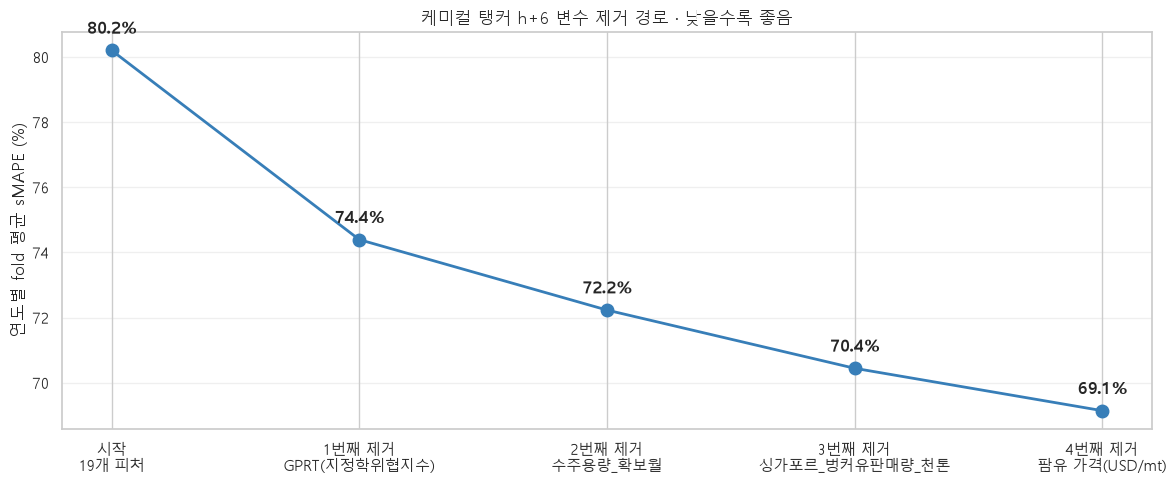

최종 모형: 랜덤 포레스트
최종 피처: 수주용량_확보월1개월전, 수주용량_확보월2개월전, 원유 평균 가격(USD/bbl), 대두유 가격(USD/mt), 천연가스 가격지수(2010=100), 글로벌_컨테이너처리량지수, 세계_실질상품수출_백만2010USD_계절조정, 세계_실질상품수입_백만2010USD_계절조정, 세계_산업생산_백만2010USD_계절조정, 글로벌_공급망압력지수(표준편차), GPR(세계지정학위험지수), GPRA(지정학행동지수), 미국TPU(EPUTRADE 무역정책불확실성지수), 미국TPU(Caldara 무역정책불확실성지수), 중국TPU(무역정책불확실성지수)


In [14]:
시작후보 = 선택['시작모형후보']
경로 = 선택['변수제거경로']
경로점수 = [100 * 시작후보['평균sMAPE']]
경로이름 = [f'시작\n{len(시작후보["피처목록"])}개 피처']
for 행 in 경로:
    경로점수.append(경로점수[-1] - 행['개선_퍼센트포인트'])
    경로이름.append(f'{행["단계"]}번째 제거\n{행["제거변수"]}')
fig, 축 = plt.subplots(figsize=(12, 5))
축.plot(range(len(경로점수)), 경로점수, marker='o', markersize=9,
        color='#377EB8', linewidth=2)
for 번호, 값 in enumerate(경로점수):
    축.annotate(f'{값:.1f}%', (번호, 값), xytext=(0, 12),
                textcoords='offset points', ha='center', fontweight='bold')
축.set_xticks(range(len(경로이름)), 경로이름)
축.set_ylabel('연도별 fold 평균 sMAPE (%)')
축.set_title(f'{선종} h+6 변수 제거 경로 · 낮을수록 좋음')
축.grid(axis='y', alpha=.3)
fig.tight_layout()
plt.show()
print('최종 모형:', 선택['모형'])
print('최종 피처:', ', '.join(선택['피처목록']))

### 3.4 최종 선택 피처와 목표 수주용량의 관계

각 점은 예측기준월 `C`에 확보 가능하다고 간주한 `D=C-3` 입력과 `D+6` 목표월의 실제 수주용량을 짝지은 것입니다. 빨간 추세선과 Pearson r은 목표월이 2024-10 이내인 자료로만 계산한 탐색용 관계이며, 예측모형의 적합선이나 독립 테스트 성능은 아닙니다.

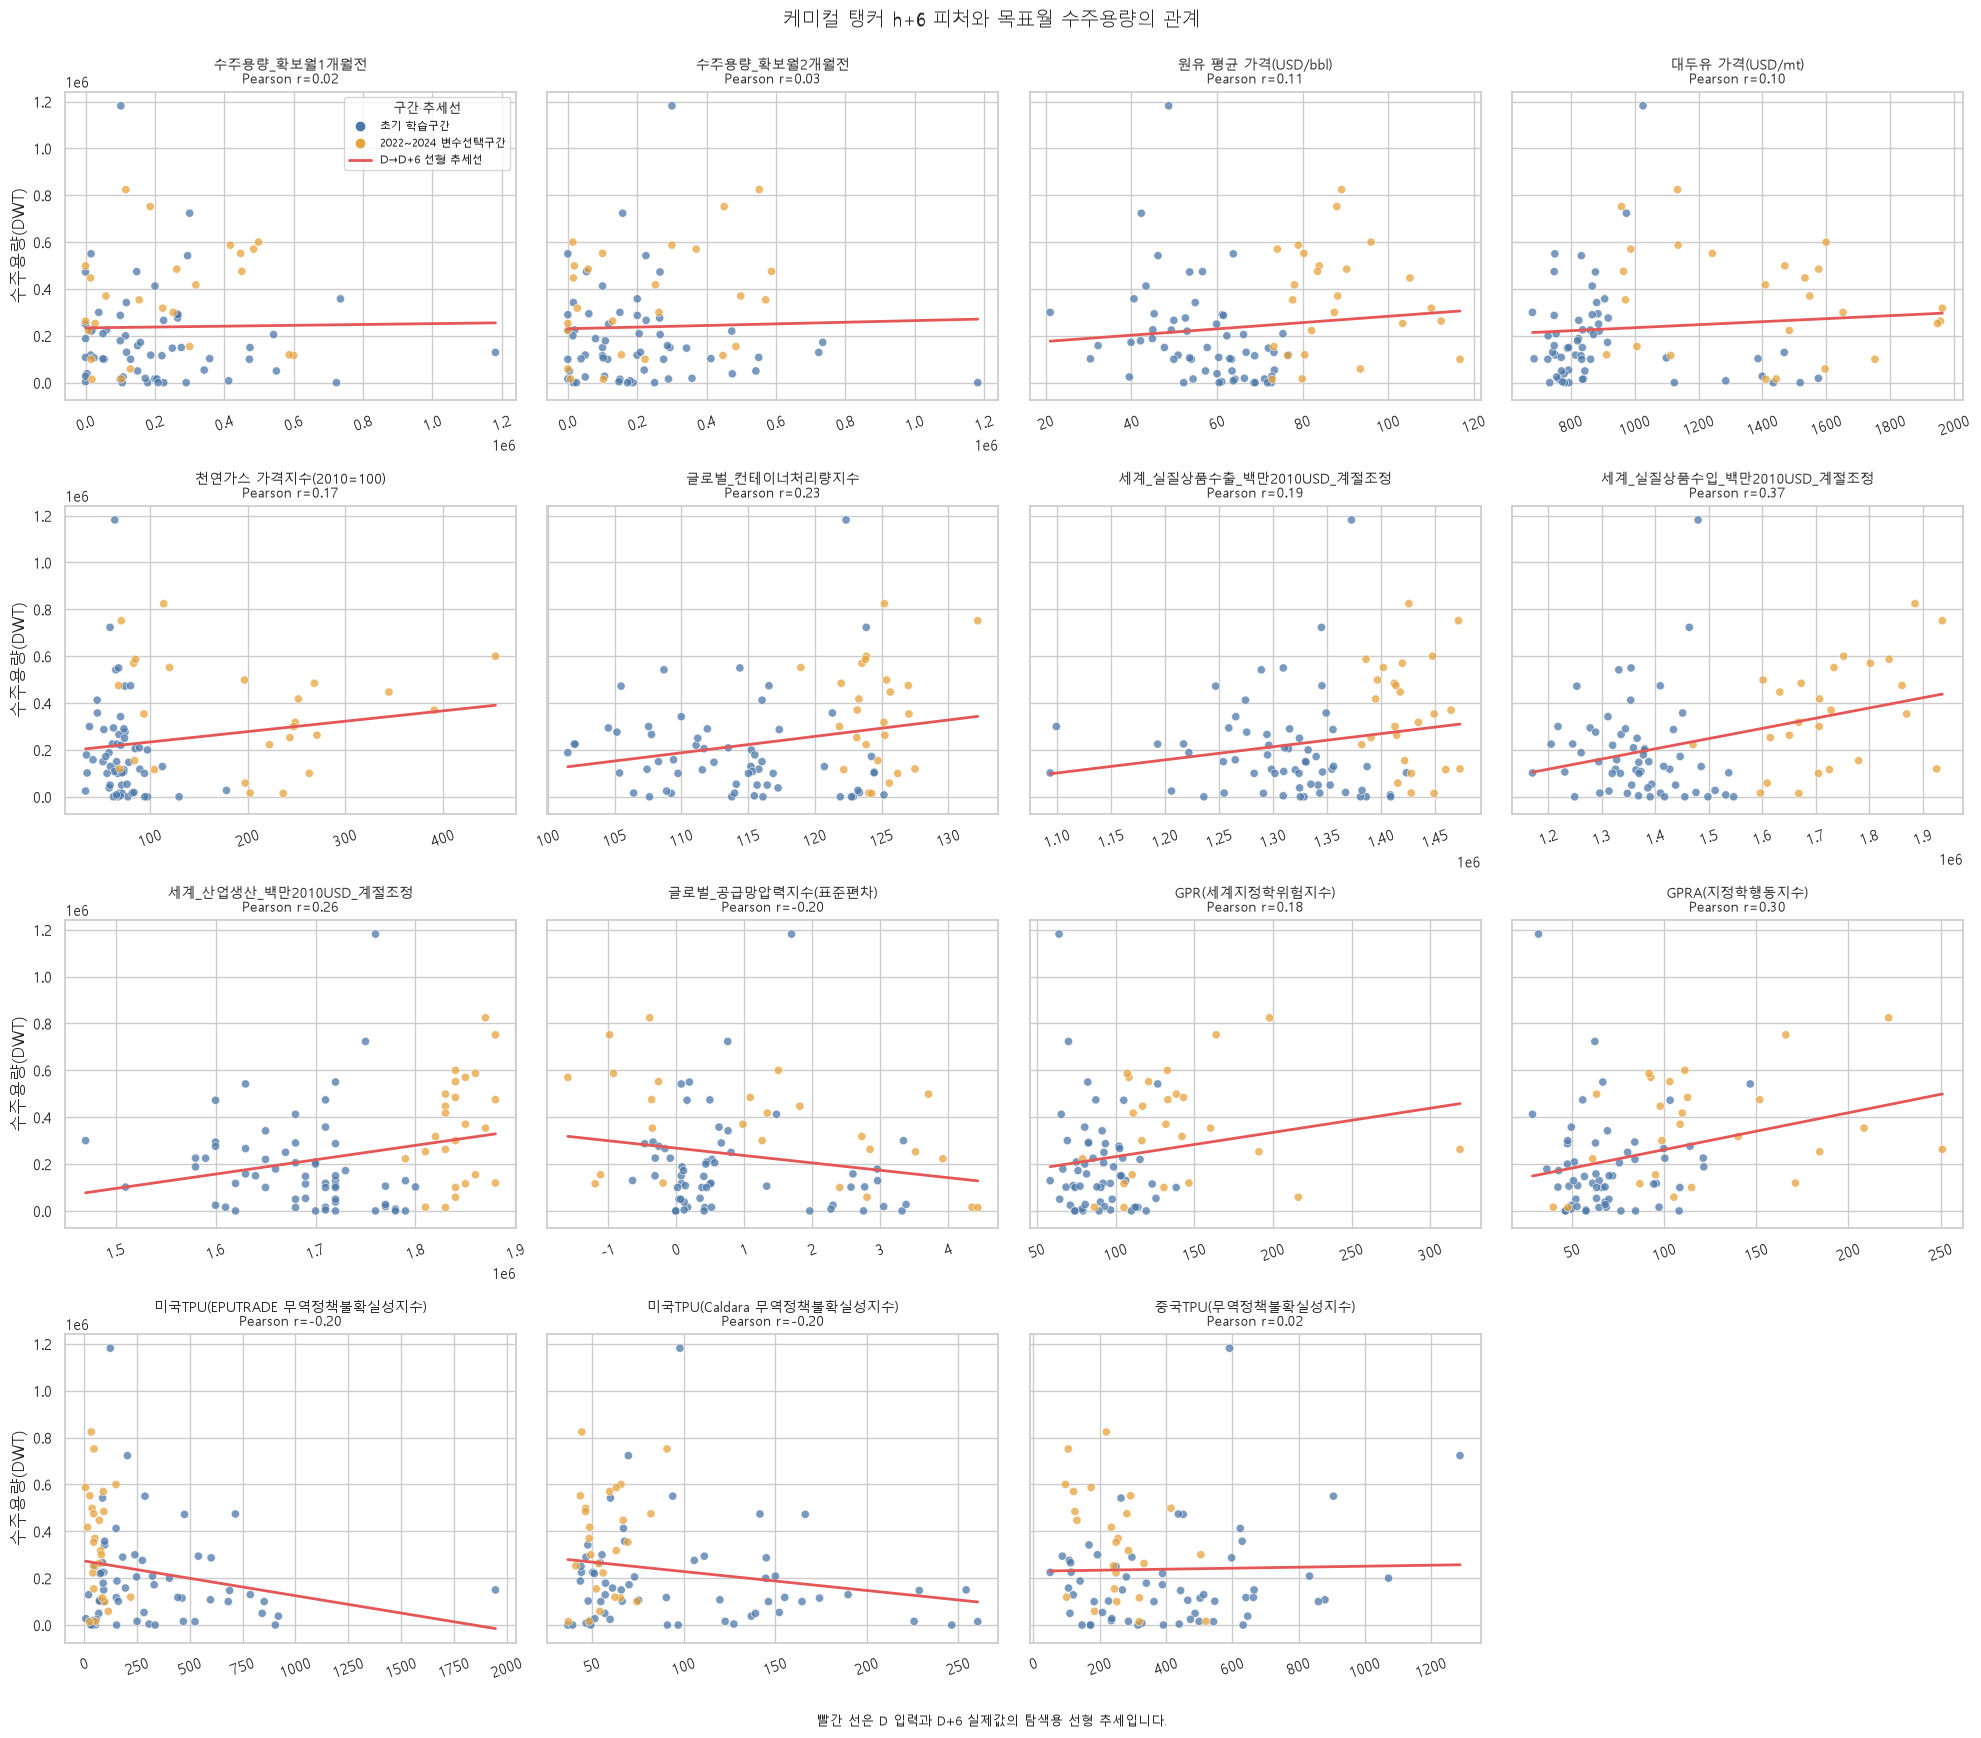

In [18]:
from matplotlib.lines import Line2D

# 동시월 마스터 값이 아니라, 각 과거 예측 기준일의 데이터마감월에 실제로
# 사용할 수 있었던 피처값과 6개월 뒤 목표값을 짝지어 그립니다.
산점도자료 = pd.DataFrame(운영결과['피처산점도자료'])
if 산점도자료.empty:
    print('시점이 맞는 최종 피처 산점도 자료가 없습니다.')
else:
    산점도자료['예측기준일'] = pd.to_datetime(산점도자료['예측기준일'])
    산점도자료['데이터마감월'] = pd.to_datetime(산점도자료['데이터마감월'])
    산점도자료['목표월'] = pd.to_datetime(산점도자료['목표월'])
    기대마감월 = (산점도자료['예측기준일'].dt.to_period('M').dt.to_timestamp()
              - pd.DateOffset(months=3))
    if not 산점도자료['데이터마감월'].eq(기대마감월).all():
        raise ValueError('산점도 입력월이 예측기준월보다 정확히 3개월 전이 아닙니다.')
    if not 산점도자료['목표월'].eq(산점도자료['데이터마감월']
                               + pd.DateOffset(months=6)).all():
        raise ValueError('산점도 목표월이 데이터마감월보다 정확히 6개월 뒤가 아닙니다.')
    산점도자료['구간'] = np.where(산점도자료['예측기준일'] < pd.Timestamp('2022-01-01'),
                           '초기 학습구간', '2022~2024 변수선택구간')
    산점도열수 = 4
    산점도행수 = int(np.ceil(len(선택['피처목록']) / 산점도열수))
    fig, 축목록 = plt.subplots(산점도행수, 산점도열수,
                           figsize=(5 * 산점도열수, 4.4 * 산점도행수),
                           squeeze=False, sharey=True)
    for 번호, (축, 피처) in enumerate(zip(축목록.flat, 선택['피처목록'])):
        sns.scatterplot(data=산점도자료, x=피처, y='실제', hue='구간',
                        hue_order=['초기 학습구간', '2022~2024 변수선택구간'],
                        palette=['#4C78A8', '#E6A23C'], alpha=.75,
                        s=35, ax=축, legend=(번호 == 0))
        if 산점도자료[피처].nunique() >= 2:
            sns.regplot(data=산점도자료, x=피처, y='실제', ax=축,
                        scatter=False, ci=None,
                        line_kws={'color': '#E45756', 'linewidth': 2})
        상관계수 = 산점도자료[[피처, '실제']].corr().iloc[0, 1]
        축.set_title(f'{피처}\nPearson r={상관계수:.2f}', fontsize=10)
        축.set_xlabel('')
        축.set_ylabel(종속변수표시명 if 번호 % 산점도열수 == 0 else '')
        축.tick_params(axis='x', labelrotation=20)
        if 번호 == 0:
            범례항목 = [
                Line2D([], [], marker='o', linestyle='none', color='#4C78A8',
                       label='초기 학습구간'),
                Line2D([], [], marker='o', linestyle='none', color='#E6A23C',
                       label='2022~2024 변수선택구간'),
                Line2D([], [], color='#E45756', linewidth=2,
                       label='D→D+6 선형 추세선'),
            ]
            축.legend(handles=범례항목, title='구간·추세선', loc='upper right',
                      fontsize=8, title_fontsize=9)
    for 축 in 축목록.flat[len(선택['피처목록']):]:
        축.axis('off')
    fig.suptitle(f'{선종} h+6 피처와 목표월 수주용량의 관계', fontsize=14)
    fig.text(.5, .005, '빨간 선은 D 입력과 D+6 실제값의 탐색용 선형 추세입니다.',
             ha='center', fontsize=9)
    fig.tight_layout(rect=[0, .02, 1, .985])
    plt.show()

## 4. 최종 h+6 모형의 월별 순차평가와 운영 예측

매월 말에 확보 가능한 자료로 동일한 h+6 예측 규칙을 다시 실행합니다. 2025~2026년의 실제값이 확인된 목표월만 오차 계산에 포함하며, 실제값이 없는 미래 목표월은 성능 점수에서 제외합니다.

### 4.1 월별·분기·반기·연간 누적 평가

In [15]:
from ship_orders_forecasting.modeling import metrics as 지표계산

진단자료 = pd.DataFrame(운영결과['개발진단']['월별예측'])
진단자료['목표월'] = pd.to_datetime(진단자료['목표월'])
진단자료 = 진단자료.sort_values('목표월').set_index('목표월')
if 진단자료.empty or 진단자료.index.duplicated().any():
    raise ValueError('h+6 개발 진단의 목표월이 비었거나 중복되었습니다.')

해상도별자료 = {'월별': 진단자료[['실제', '예측']]}
상세행 = []
for 이름, 월수 in [('분기 누적', 3), ('반기 누적', 6), ('연간 누적', 12)]:
    완전한구간 = []
    for (연도, 묶음), 부분 in 진단자료.groupby([
        진단자료.index.year, (진단자료.index.month - 1) // 월수
    ]):
        시작 = pd.Timestamp(year=int(연도), month=int(묶음) * 월수 + 1, day=1)
        예상월 = pd.date_range(시작, periods=월수, freq='MS')
        if 부분.index.equals(예상월):
            실제합 = 부분['실제'].sum()
            예측합 = 부분['예측'].sum()
            완전한구간.append({'시작월': 시작, '실제': 실제합, '예측': 예측합})
            상세행.append({'평가단위': 이름, '기간': f'{시작:%Y-%m}~{예상월[-1]:%Y-%m}',
                      f'실제누적({목표단위})': 실제합,
                      f'예측누적({목표단위})': 예측합,
                      f'예측-실제({목표단위})': 예측합 - 실제합})
    해상도별자료[이름] = (pd.DataFrame(완전한구간).set_index('시작월')
                   if 완전한구간 else pd.DataFrame(columns=['실제', '예측']))

평가행 = []
for 이름, 부분 in 해상도별자료.items():
    점수 = 지표계산(부분['실제'], 부분['예측']) if len(부분) else None
    평가행.append({'평가단위': 이름, '완전한 평가구간 수': len(부분),
            'sMAPE(%)': 100 * 점수['sMAPE'] if 점수 else np.nan,
            f'MAE({목표단위})': 점수['MAE'] if 점수 else np.nan,
            f'RMSE({목표단위})': 점수['RMSE'] if 점수 else np.nan,
            'R²(월별만)': 점수['R2'] if 점수 and 이름 == '월별' else np.nan,
            '상태': '평가 가능' if 점수 else '완전한 기간 없음'})
display(pd.DataFrame(평가행).round(2))
if 상세행:
    display(pd.DataFrame(상세행).round(0))
print('누적점수는 매월 새 기준일에서 예측한 h+6 단일월 값의 사후 합계입니다.')
print('완전한 연도가 없으면 연간 점수를 만들지 않습니다.')

,평가단위,완전한 평가구간 수,sMAPE(%),MAE(DWT),RMSE(DWT),R²(월별만),상태
0,월별,17,80.02,333816.20,396431.32,-0.46,평가 가능
1,분기 누적,5,54.90,595149.98,691383.66,NaN,평가 가능
2,반기 누적,2,46.99,1134075.57,1346536.40,NaN,평가 가능
3,연간 누적,0,NaN,NaN,NaN,NaN,완전한 기간 없음


,평가단위,기간,실제누적(DWT),예측누적(DWT),예측-실제(DWT)
0,분기 누적,2025-04~2025-06,454652.0,1162251.0,707599.0
1,분기 누적,2025-07~2025-09,1138690.0,935162.0,-203528.0
2,분기 누적,2025-10~2025-12,1021498.0,816921.0,-204577.0
3,분기 누적,2026-01~2026-03,1577490.0,842659.0,-734831.0
4,분기 누적,2026-04~2026-06,1896300.0,771085.0,-1125215.0
5,반기 누적,2025-07~2025-12,2160188.0,1752083.0,-408105.0
6,반기 누적,2026-01~2026-06,3473790.0,1613744.0,-1860046.0


누적점수는 매월 새 기준일에서 예측한 h+6 단일월 값의 사후 합계입니다.
완전한 연도가 없으면 연간 점수를 만들지 않습니다.


### 4.2 월별 실제·순차예측선과 현재 운영 예측

개발 구간과 운영 구간에 **동일한 h+6 규칙**을 적용합니다. 마지막 6개월은 2026년 2~7월 자료에서 각각 여섯 달 뒤를 예측한 값이며, 그 구간의 실제값은 표시하지 않습니다. 각 월말의 D=C-3 자료월 경계까지의 입력으로 재학습하며 사후 확보한 관측값도 포함될 수 있습니다. 배경색은 초기 학습·선택모형 참고·개발 진단·운영 전망의 **구간 역할**을 나타내며 예측 신뢰도를 뜻하지 않습니다. 파란 참고선은 2025년 3월까지 이어 그리지만, 추가한 2024년 11월~2025년 3월은 변수 선택 점수에 넣지 않습니다. 선이 끊긴 달은 관측값이나 자료월 경계 안의 입력이 없어 0·보간값으로 메우지 않은 경우입니다.

2026-08~2027-01 월별 h+6 운영 전망 (DWT)


,데이터마감월,목표월,예측,학습행수
0,2026-02,2026-08,317115.0,100
1,2026-03,2026-09,433963.0,101
2,2026-04,2026-10,465318.0,102
3,2026-05,2026-11,473386.0,103
4,2026-06,2026-12,515863.0,104
5,2026-07,2027-01,686420.0,105


,목표월,계열,실제투입피처,학습상관계수
0,2026-08,미국TPU,미국TPU(Caldara 무역정책불확실성지수),0.053085
1,2026-08,세계거시,세계_실질상품수입_백만2010USD_계절조정,0.317940
2,2026-08,지정학,GPRA(지정학행동지수),0.295956
3,2026-09,미국TPU,미국TPU(Caldara 무역정책불확실성지수),0.075261
4,2026-09,세계거시,세계_실질상품수입_백만2010USD_계절조정,0.335045
5,2026-09,지정학,GPRA(지정학행동지수),0.299014
6,2026-10,미국TPU,미국TPU(Caldara 무역정책불확실성지수),0.109870
7,2026-10,세계거시,세계_실질상품수입_백만2010USD_계절조정,0.368573
8,2026-10,지정학,GPRA(지정학행동지수),0.318109
9,2026-11,미국TPU,미국TPU(Caldara 무역정책불확실성지수),0.110858


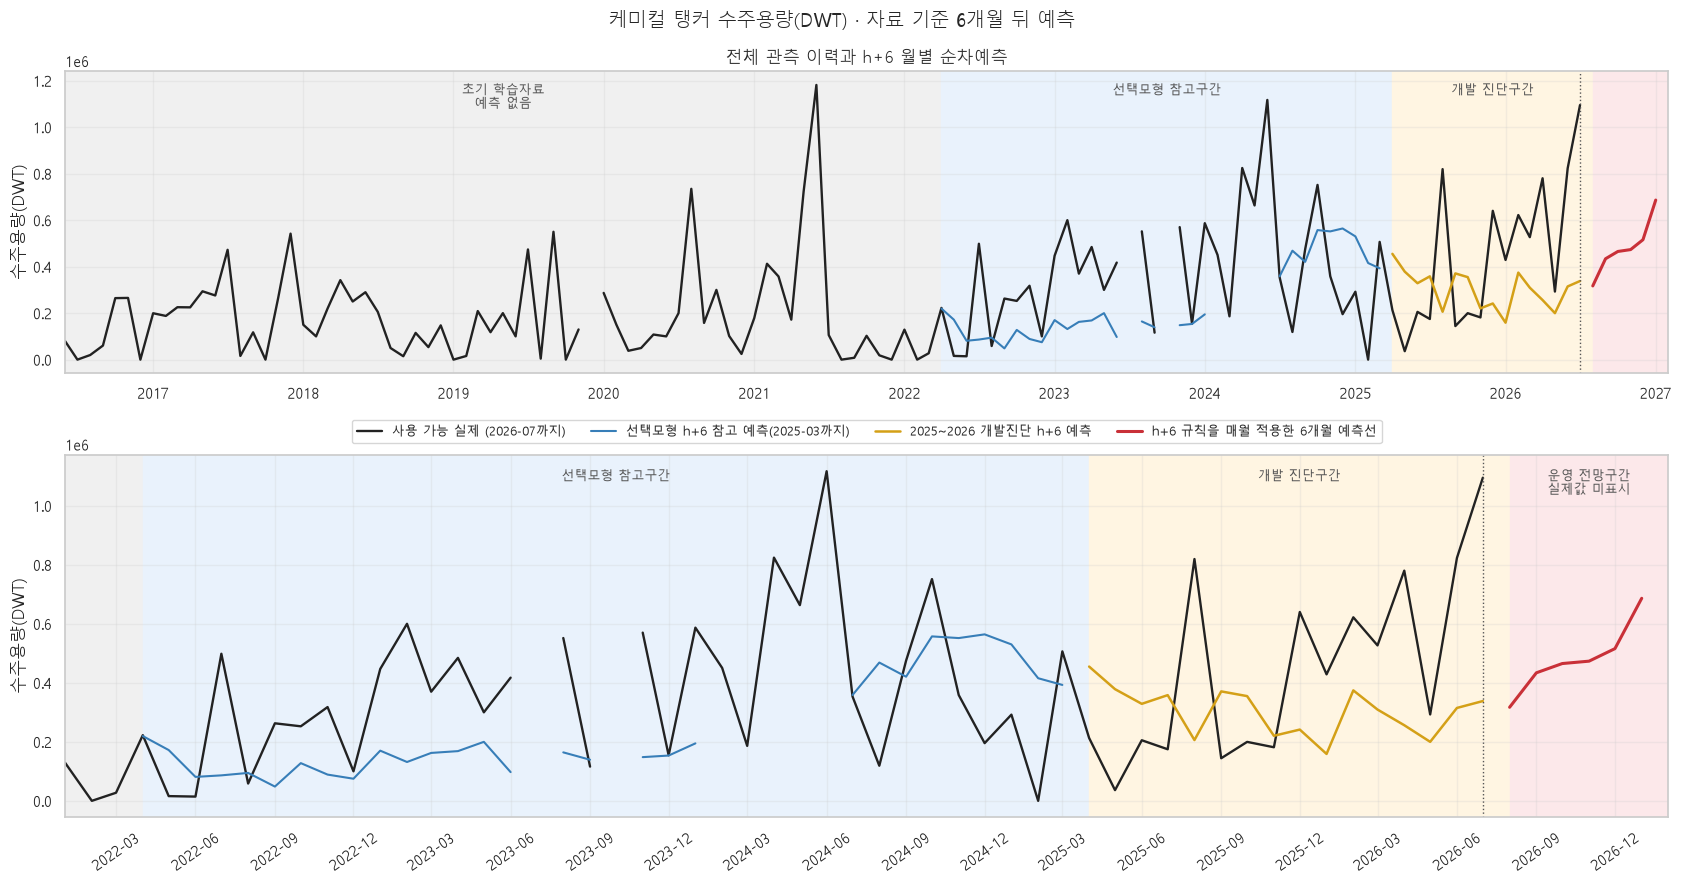

In [16]:
import matplotlib.dates as mdates

print(f'2026-08~2027-01 월별 h+6 운영 전망 ({목표단위})')
운영전망표 = 운영전망선[['데이터마감월', '목표월', '예측', '학습행수']].copy()
운영전망표['데이터마감월'] = 운영전망표['데이터마감월'].dt.strftime('%Y-%m')
운영전망표['목표월'] = 운영전망표['목표월'].dt.strftime('%Y-%m')
display(운영전망표.round(0))
if 운영전망선['예측'].isna().any():
    print('빈 예측값은 원천 수주자료 결측으로 산출할 수 없는 월입니다.')
운영계열선택 = pd.DataFrame([
    {'목표월': 행['목표월'], '계열': 계열, '실제투입피처': 값['선택'],
     '학습상관계수': 값['학습상관계수']}
    for 행 in 운영결과['2026-10_6개월전망선']
    for 계열, 값 in 행.get('상관선택', {}).items()
])
if not 운영계열선택.empty:
    display(운영계열선택)

선택참고 = pd.DataFrame(운영결과['선택구간순차예측_참고'])
if not 선택참고.empty:
    선택참고['목표월'] = pd.to_datetime(선택참고['목표월'])
    선택참고 = 선택참고.sort_values('목표월').set_index('목표월')
연결월 = pd.date_range('2024-11-01', '2025-03-01', freq='MS')
if 선택참고.empty or not 연결월.isin(선택참고.index).all():
    raise ValueError('선택모형 참고 예측선의 2024-11~2025-03 연결월이 빠졌습니다.')
확보실제 = 자료.loc[자료.index <= 데이터마감월, 종속변수]
if 데이터마감월 not in 확보실제.index or pd.isna(확보실제.loc[데이터마감월]):
    raise ValueError('2026-07 실제 수주용량이 없어 운영 예측 입력 경계를 확인할 수 없습니다.')
보이는진단 = 진단자료.loc[진단자료.index <= 데이터마감월]
선택시작월 = 선택참고.index.min() if not 선택참고.empty else None
선택끝다음월 = (선택참고.index.max() + pd.DateOffset(months=1)
             if not 선택참고.empty else None)
개발시작월 = 보이는진단.index.min()
운영시작월 = 운영전망선['목표월'].min()
운영끝다음월 = 운영전망선['목표월'].max() + pd.DateOffset(months=1)
배경구간 = [
    (확보실제.index.min(), 선택시작월, '#F0F0F0', '초기 학습자료\n예측 없음'),
    (선택시작월, 선택끝다음월, '#E9F2FC', '선택모형 참고구간'),
    (개발시작월, 운영시작월, '#FFF5E2', '개발 진단구간'),
    (운영시작월, 운영끝다음월, '#FCE8EA', '운영 전망구간\n실제값 미표시'),
]
fig, 축목록 = plt.subplots(2, 1, figsize=(17, 9), height_ratios=[1, 1.2])
for 축, 시작월 in zip(축목록, [확보실제.index.min(), pd.Timestamp('2022-01-01')]):
    표시끝월 = 운영끝다음월
    전체폭 = (표시끝월 - 시작월).days
    for 구간시작, 구간끝, 배경색, 구간명 in 배경구간:
        if 구간시작 is None or 구간끝 is None or 구간시작 >= 구간끝:
            continue
        축.axvspan(구간시작, 구간끝, color=배경색, zorder=0)
        보이는시작 = max(구간시작, 시작월)
        보이는끝 = min(구간끝, 표시끝월)
        if 보이는시작 < 보이는끝 and (보이는끝 - 보이는시작).days / 전체폭 >= .08:
            중앙월 = 보이는시작 + (보이는끝 - 보이는시작) / 2
            축.text(중앙월, .96, 구간명, transform=축.get_xaxis_transform(),
                    ha='center', va='top', fontsize=9, color='#555555')
    전체월 = pd.date_range(시작월, 데이터마감월, freq='MS')
    축.plot(전체월, 확보실제.reindex(전체월), color='#222222', linewidth=1.7,
            label='사용 가능 실제 (2026-07까지)')
    if not 선택참고.empty:
        축.plot(전체월, 선택참고['예측'].reindex(전체월), color='#377EB8', linewidth=1.5,
                label='선택모형 h+6 참고 예측(2025-03까지)')
    축.plot(전체월, 보이는진단['예측'].reindex(전체월), color='#D4A017', linewidth=1.8,
            label='2025~2026 개발진단 h+6 예측')
    축.plot(운영전망선['목표월'], 운영전망선['예측'],
            color='#C93038', linewidth=2.2, zorder=5,
            label='h+6 규칙을 매월 적용한 6개월 예측선')
    축.axvline(데이터마감월, color='#555555', linestyle=':', linewidth=1)
    축.set_xlim(시작월, 표시끝월)
    축.set_ylabel(종속변수표시명)
    축.grid(alpha=.25)
    축.xaxis.set_major_locator(mdates.YearLocator() if 시작월.year < 2020
                             else mdates.MonthLocator(interval=3))
    축.xaxis.set_major_formatter(mdates.DateFormatter('%Y' if 시작월.year < 2020 else '%Y-%m'))
축목록[0].set_title('전체 관측 이력과 h+6 월별 순차예측')
축목록[1].tick_params(axis='x', rotation=35)
축목록[1].legend(loc='lower center', bbox_to_anchor=(.5, 1.015), ncol=4, fontsize=9)
fig.suptitle(f'{선종} {종속변수표시명} · 자료 기준 6개월 뒤 예측', fontsize=14)
fig.tight_layout()
plt.show()

### 4.3 최종 피처 중요도

,피처,제거피처목록,제거시평균sMAPE,제거시sMAPE증가_퍼센트포인트,fold별증가_퍼센트포인트
0,미국TPU 계열 전체,"[미국TPU(EPUTRADE 무역정책불확실성지수), 미국TPU(Caldara 무역정...",0.69,0.02,"{'2022': 0.286626560489478, '2023': -1.8610659..."
1,세계거시 계열 전체,"[세계_실질상품수출_백만2010USD_계절조정, 세계_실질상품수입_백만2010USD...",0.74,4.52,"{'2022': 0.16715355201388782, '2023': 1.404768..."
2,지정학 계열 전체,"[GPR(세계지정학위험지수), GPRA(지정학행동지수)]",0.72,2.52,"{'2022': -2.571410351745762, '2023': 7.4935490..."
3,수주용량_확보월1개월전,[수주용량_확보월1개월전],0.71,2.28,"{'2022': -3.547292332385088, '2023': 6.4256184..."
4,수주용량_확보월2개월전,[수주용량_확보월2개월전],0.71,1.95,"{'2022': -2.746973878347303, '2023': -0.324227..."
5,원유 평균 가격(USD/bbl),[원유 평균 가격(USD/bbl)],0.71,1.89,"{'2022': 1.602734979286513, '2023': 2.67633145..."
6,대두유 가격(USD/mt),[대두유 가격(USD/mt)],0.71,2.23,"{'2022': 1.5474830627815073, '2023': 4.1597996..."
7,천연가스 가격지수(2010=100),[천연가스 가격지수(2010=100)],0.70,0.99,"{'2022': -0.8713096069481563, '2023': 3.072078..."
8,글로벌_컨테이너처리량지수,[글로벌_컨테이너처리량지수],0.70,0.60,"{'2022': 0.4955559964173961, '2023': 0.1096542..."
9,글로벌_공급망압력지수(표준편차),[글로벌_공급망압력지수(표준편차)],0.73,3.76,"{'2022': 0.8537868644880264, '2023': 8.0891907..."


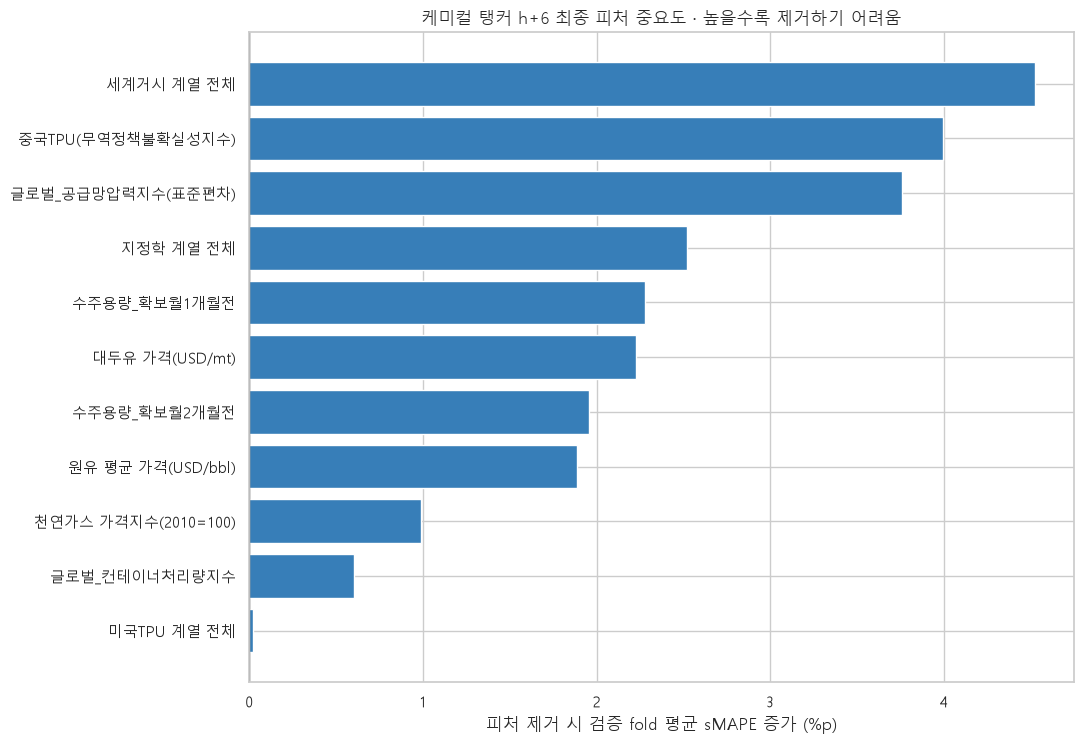

In [17]:
# 단일 피처 또는 상관선택 계열 전체를 빼고 같은 2022~2024 fold를 다시 평가한 sMAPE 변화.
# 음수면 오히려 제거했을 때 좋아지는 피처라 비율형 도넛보다 부호 있는 막대가 적절합니다.
중요도표 = pd.DataFrame(선택['최종피처제거중요도'])
if 중요도표.empty:
    print('평가 가능한 최종 피처 제거 중요도가 없습니다.')
else:
    display(중요도표.round(2))
    중요도표 = 중요도표.sort_values('제거시sMAPE증가_퍼센트포인트')
    값 = 중요도표['제거시sMAPE증가_퍼센트포인트']
    fig, 축 = plt.subplots(figsize=(11, max(3.5, .6 * len(중요도표) + 1)))
    축.barh(중요도표['피처'], 값,
            color=['#377EB8' if 항목 >= 0 else '#E45756' for 항목 in 값])
    축.axvline(0, color='#555555', linewidth=1)
    축.set_xlabel('피처 제거 시 검증 fold 평균 sMAPE 증가 (%p)')
    축.set_title(f'{선종} h+6 최종 피처 중요도 · 높을수록 제거하기 어려움')
    fig.tight_layout()
    plt.show()

## 5. 과거 연도별 재현 평가

4절은 현재 선택된 변수 조합의 결과입니다. 이 절은 **평가 연도마다 변수·모형 선택부터 과거 시점에서 다시 실행**해, 특정 해에만 잘 맞는지 확인합니다. 2023~2026년의 각 1월 말에 D=C-3 자료월 경계와 직전 3개 연도 walk-forward fold를 적용해 선택합니다. 선택된 변수·모형은 그해 동안 고정하되, 회귀모형은 매월 새 데이터마감월까지의 학습 라벨로 재학습합니다. 개별 수주 기사 게시일은 제한하지 않습니다. 예측 규칙은 4절과 같은 `C-3=D`, 목표월 `D+6`입니다.

2026년은 현재 관측 가능한 목표월까지만 평가하는 부분연도입니다. 이미 과거 결과를 분석에 활용했으므로 이 재현 점수를 새 독립 테스트 성능으로 주장하지 않습니다. 결측 때문에 평가하지 못한 월도 점수에서 숨기지 않고 별도로 셉니다.


### 5.1 연도 시작 시점에서 변수 다시 선택

각 기준연도의 1월 말에 확보할 수 있던 목표값까지만 내부 fold에 넣습니다. 이후 그해의 모든 월에 동일한 선택 규칙을 적용합니다.


In [19]:
from ship_orders_forecasting.nested_backtest import annual_replay
from ship_orders_forecasting.publication_lag_forecast import ORDER_LAGS

재현후보 = {'전체 후보': list(dict.fromkeys([*ORDER_LAGS.values(), *외부피처]))}
if 재현후보 != 분석결과['후보군']:
    raise ValueError('5절과 2~4절의 후보 변수 집합이 다릅니다.')
재현결과 = annual_replay(
    시점프레임, 외부피처, 수주게시일, 재현후보,
    years=(2023, 2024, 2025, 2026), horizon=6,
)
print('연도별 재현 평가: 매년 1월에 직전 3개 연도 fold로 변수·모형 재선택')
print('선택 변수는 해당 기준연도 안에서 고정, 회귀모형만 매월 재학습')


연도별 재현 평가: 매년 1월에 직전 3개 연도 fold로 변수·모형 재선택
선택 변수는 해당 기준연도 안에서 고정, 회귀모형만 매월 재학습


### 5.2 연도별 성능·평가 가능 월·변수 안정성

표의 연도는 **예측 기준월의 연도**입니다. h+6 목표월은 해당 연도 4월부터 다음 해 3월까지입니다. 2026년은 부분연도이고, 연도마다 평가 가능한 월수가 다르므로 평균과 표준편차는 보조적으로 해석합니다.


,예측 기준연도,선택 시 최신 자료월,내부 선택 fold,예측 기준월수,목표 실제 관측월수,평가월수,sMAPE(%),MAE(DWT),RMSE(DWT),상태
0,2023,2022-10,"2020: 7개월, 2021: 12개월, 2022: 7개월",12,10,8,73.9,217442.3,251089.6,12개월 기준연도
1,2024,2023-10,"2021: 12개월, 2022: 12개월, 2023: 5개월",12,12,9,63.7,190853.3,227633.6,12개월 기준연도
2,2025,2024-10,"2022: 12개월, 2023: 7개월, 2024: 4개월",12,12,12,76.6,254878.3,291271.5,12개월 기준연도
3,2026,2025-10,"2023: 7개월, 2024: 9개월, 2025: 7개월",10,5,5,86.8,519062.3,571672.1,진행 중인 기준연도


연도별 sMAPE 단순 평균 75.2% · 연도 간 표준편차 9.5%p (점수 있는 연도 4개, 2026 부분연도 포함)
평가 가능한 모든 월 34개의 통합 sMAPE: 74.0%


,예측 기준연도,선택 모형,선택 피처 수,선택 피처,순차 제거 피처
0,2023,랜덤 포레스트,16,"수주용량_확보월, 수주용량_확보월1개월전, 원유 평균 가격(USD/bbl), 팜유 ...","수주용량_확보월2개월전, GPRT(지정학위협지수), 미국TPU(Caldara 무역정..."
1,2024,랜덤 포레스트,16,"수주용량_확보월, 수주용량_확보월1개월전, 수주용량_확보월2개월전, 원유 평균 가격...","GPRT(지정학위협지수), 싱가포르_벙커유판매량_천톤, 세계_실질상품수출_백만201..."
2,2025,랜덤 포레스트,15,"수주용량_확보월1개월전, 수주용량_확보월2개월전, 원유 평균 가격(USD/bbl),...","GPRT(지정학위협지수), 수주용량_확보월, 싱가포르_벙커유판매량_천톤, 팜유 가격..."
3,2026,랜덤 포레스트,15,"수주용량_확보월, 수주용량_확보월2개월전, 원유 평균 가격(USD/bbl), 팜유 ...","수주용량_확보월1개월전, 중국TPU(무역정책불확실성지수), 세계_실질상품수입_백만2..."


평가에서 제외된 월과 사유 (실제 미관측·입력 결측을 0으로 채우지 않음)


,예측기준월,목표월,상태,결측입력
3,2023-04,2023-07,실제 미관측,[]
6,2023-07,2023-10,실제 미관측,[]
9,2023-10,2024-01,입력 결측,[수주용량_확보월]
10,2023-11,2024-02,입력 결측,[수주용량_확보월1개월전]
12,2024-01,2024-04,입력 결측,[수주용량_확보월]
13,2024-02,2024-05,입력 결측,[수주용량_확보월1개월전]
14,2024-03,2024-06,입력 결측,[수주용량_확보월2개월전]
41,2026-06,2026-09,실제 미관측,[]
42,2026-07,2026-10,실제 미관측,[]
43,2026-08,2026-11,실제 미관측,[]


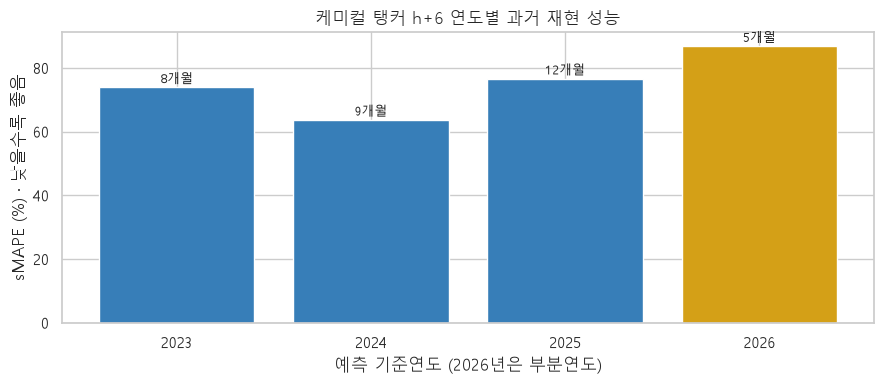

In [20]:
재현요약 = pd.DataFrame(재현결과['연도별'])
재현월별 = pd.DataFrame(재현결과['월별'])
연도별점수 = pd.DataFrame([{
    '예측 기준연도': 행['기준연도'],
    '선택 시 최신 자료월': 행['선택시최신자료월'],
    '내부 선택 fold': ', '.join(f'{연도}: {월수}개월'
                          for 연도, 월수 in 행.get('내부fold별월수', {}).items()),
    '예측 기준월수': 행['기준월수'],
    '목표 실제 관측월수': 행.get('목표실제관측월수', 0),
    '평가월수': 행['평가월수'],
    'sMAPE(%)': 100 * 행['sMAPE'] if pd.notna(행['sMAPE']) else np.nan,
    f'MAE({목표단위})': 행['MAE'],
    f'RMSE({목표단위})': 행['RMSE'],
    '상태': 행['상태'],
} for 행 in 재현결과['연도별']])
display(연도별점수.round(1))

유효연도점수 = 연도별점수['sMAPE(%)'].dropna()
유효월 = 재현월별.loc[재현월별['상태'].eq('평가')]
재현전체점수 = (지표계산(유효월['실제'], 유효월['예측'])
           if not 유효월.empty else None)
print(f'연도별 sMAPE 단순 평균 {유효연도점수.mean():.1f}% · '
      f'연도 간 표준편차 {유효연도점수.std(ddof=1):.1f}%p '
      f'(점수 있는 연도 {len(유효연도점수)}개, 2026 부분연도 포함)')
if 재현전체점수:
    print(f'평가 가능한 모든 월 {len(유효월)}개의 통합 sMAPE: '
          f'{100 * 재현전체점수["sMAPE"]:.1f}%')

선택안정성 = pd.DataFrame([{
    '예측 기준연도': 행['기준연도'],
    '선택 모형': 행['모형'],
    '선택 피처 수': len(행['피처목록']),
    '선택 피처': ', '.join(행['피처목록']),
    '순차 제거 피처': ', '.join(행.get('제거피처', [])) or '없음',
} for 행 in 재현결과['연도별']])
display(선택안정성)

평가제외 = 재현월별.loc[재현월별['상태'].ne('평가')]
if not 평가제외.empty:
    print('평가에서 제외된 월과 사유 (실제 미관측·입력 결측을 0으로 채우지 않음)')
    display(평가제외[['예측기준월', '목표월', '상태', '결측입력']])

그릴점수 = 연도별점수.dropna(subset=['sMAPE(%)'])
if not 그릴점수.empty:
    fig, 축 = plt.subplots(figsize=(9, 4))
    색 = ['#D4A017' if 상태 == '진행 중인 기준연도' else '#377EB8'
         for 상태 in 그릴점수['상태']]
    막대 = 축.bar(그릴점수['예측 기준연도'].astype(str), 그릴점수['sMAPE(%)'], color=색)
    for 항목, 월수 in zip(막대, 그릴점수['평가월수']):
        축.annotate(f'{월수}개월', (항목.get_x() + 항목.get_width()/2, 항목.get_height()),
                xytext=(0, 3), textcoords='offset points', ha='center', fontsize=9)
    축.set_ylabel('sMAPE (%) · 낮을수록 좋음')
    축.set_xlabel('예측 기준연도 (2026년은 부분연도)')
    축.set_title(f'{선종} h+6 연도별 과거 재현 성능')
    fig.tight_layout()
    plt.show()
